# Generating radiology reports from IU chest X-rays
**Taarak Parashar · 23CSU308 · Deep Learning**

The input is one frontal chest X-ray. The final output is a draft made from the findings and impression sections of a radiology report. The first experiments ask whether an image contains enough information to predict a study’s MeSH normal/abnormal tag. The generation experiments ask what text a model can produce from the image alone.

| Stage | Experiment | Evidence to retain |
|---|---|---|
| 1 | Inspect reports, projections and one frontal image per study | Cohort, exclusions and split manifest |
| 2 | HOG and local texture features with SVM and random forest | Accuracy, F1, AUROC and confusion matrices |
| 3 | Fixed and tuned fully connected networks on pretrained image features | Validation search table and held-out metrics |
| 4 | Three-block versus five-block CNN classifiers, then CNN–LSTM captioning | Depth comparison, loss curves and generated examples |
| 5 | DenseNet spatial features and a Transformer language decoder | Validation ablation, held-out BLEU and ROUGE, error review |
| 6 | Streamlit upload, generate and download | Portable model bundle and GitHub-ready app folder |

**First run.** Use a Python 3.11 notebook kernel. If you have an NVIDIA GPU, install a matching CUDA build of PyTorch and torchvision in that kernel before running setup. Set `DATA_DIR` to the extracted Kaggle folder. `QUICK_TEST=True` exercises the pipeline on a small cohort. Set it to `False` and restart the kernel for final figures. Pretrained weights require internet on first use. The quick and full runs have separate output folders.

The default is the full run. The final stage fine-tunes the last DenseNet block with IU indexing tags and conditions generation on image-predicted findings. Use the checkpoint created by this version for the app.

In [ ]:
%pip install "torch>=2.2" torchvision scikit-learn scikit-image pandas numpy matplotlib seaborn pillow tqdm nltk streamlit

## 1 · Configuration and dataset audit

In [1]:
import os, re, sys, glob, json, time, math, random, copy, hashlib, warnings, traceback
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)

from pathlib import Path
import uuid
sns.set_theme(style="whitegrid")


DATA_DIR         = "D:/archive"
QUICK_TEST       = False
PRETRAINED       = True
BACKBONES        = ["resnet50", "densenet121"]
IMG_SIZE         = 224
CUSTOM_CNN_SIZE  = 128
SEED             = 42


MIN_WORD_FREQ    = 3
MAX_TOKENS_CAP   = 100
EMBED, HIDDEN, LSTM_LAYERS, DROPOUT = 256, 512, 1, 0.3
EPOCHS_DECODER   = 30
EPOCHS_CUSTOM    = 15
BATCH_DECODER, BATCH_CUSTOM = 64, 32
BEAM_SIZE        = 3
NO_REPEAT_NGRAM  = 4


TF_BACKBONE      = "densenet121"
TF_D_MODEL       = 256
TF_HEADS         = 8
TF_ENC_LAYERS    = 2
TF_DEC_LAYERS    = 3
TF_FF            = 512
TF_DROPOUT       = 0.2
EPOCHS_TF        = 30
BATCH_TF         = 32
LR_TF            = 5e-4


ANN_TRIALS       = 12

QUICK_N = 300
if QUICK_TEST:
    EPOCHS_DECODER, EPOCHS_CUSTOM, ANN_TRIALS = 2, 2, 3
    EPOCHS_TF = 3
    MIN_WORD_FREQ = 2

CACHE_DIR   = "cache_quick" if QUICK_TEST else "cache"
RESULTS_DIR = str(Path("iu_runs") / ("quick" if QUICK_TEST else "full") / uuid.uuid4().hex[:10])
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
set_seed()

def save_json(path, obj):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)

def load_json(path, default):
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return default

print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "no GPU found (CPU only)")
print("QUICK_TEST:", QUICK_TEST, "| results ->", RESULTS_DIR)

def save_array(path, values):
    target = Path(path)
    temp = target.with_name(f"{target.stem}-{uuid.uuid4().hex}.npy")
    try:
        np.save(temp, values)
        temp.replace(target)
    finally:
        temp.unlink(missing_ok=True)


d:\archive\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu | no GPU found (CPU only)
QUICK_TEST: False | results -> iu_runs\full\a1d1656d70


In [2]:
def find_file(name):
    hits = glob.glob(os.path.join(DATA_DIR, "**", name), recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found under {DATA_DIR}")
    if len(hits) != 1:
        raise ValueError(f"Found {len(hits)} copies of {name}. Point DATA_DIR at one dataset.")
    return hits[0]

reports = pd.read_csv(find_file("indiana_reports.csv"))
proj = pd.read_csv(find_file("indiana_projections.csv"))

IMG_INDEX = {}
for ext in ("png", "jpg", "jpeg"):
    for p in glob.glob(os.path.join(DATA_DIR, "**", f"*.{ext}"), recursive=True):
        filename = os.path.basename(p)
        if filename in IMG_INDEX:
            raise ValueError(f"Duplicate image filename {filename}. Select one extracted dataset.")
        IMG_INDEX[filename] = p
proj["path"] = proj["filename"].map(IMG_INDEX)
print("Reports:", reports.shape, "| Projections:", proj.shape, "| image files found:", len(IMG_INDEX))
print("Projection rows without an image file:", proj["path"].isna().sum())
proj = proj.dropna(subset=["path"]).reset_index(drop=True)
reports.head(3)

Reports: (3851, 8) | Projections: (7466, 4) | image files found: 7470
Projection rows without an image file: 0


,uid,MeSH,Problems,image,indication,comparison,findings,impression
0,1,normal,normal,Xray Chest PA and Lateral,Positive TB test,None.,The cardiac silhouette and mediastinum size ar...,Normal chest x-XXXX.
1,2,Cardiomegaly/borderline;Pulmonary Artery/enlarged,Cardiomegaly;Pulmonary Artery,"Chest, 2 views, frontal and lateral",Preop bariatric surgery.,None.,Borderline cardiomegaly. Midline sternotomy XX...,No acute pulmonary findings.
2,3,normal,normal,Xray Chest PA and Lateral,"rib pain after a XXXX, XXXX XXXX steps this XX...",NaN,NaN,"No displaced rib fractures, pneumothorax, or p..."


In [3]:
TOKEN_RE = re.compile(r"[a-z0-9]+|[.,]")
def tok(text):
    return TOKEN_RE.findall(str(text).lower())

def clean(text):
    if pd.isna(text):
        return ""
    t = str(text).lower()
    t = re.sub(r"x{2,}", " ", t)
    t = re.sub(r"[^a-z0-9\s\.,]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df = reports.copy()
df["findings_clean"] = df["findings"].apply(clean)
df["impression_clean"] = df["impression"].apply(clean)
df["report"] = (df["findings_clean"] + " " + df["impression_clean"]).str.strip()
print("Studies:", len(df), "| empty findings:", (df.findings_clean == "").sum(),
      "| empty impression:", (df.impression_clean == "").sum(), "| empty report:", (df.report == "").sum())
df = df[df["report"] != ""].reset_index(drop=True)

df["MeSH"] = df["MeSH"].fillna("")
mesh_l = df["MeSH"].str.lower().str.strip()
unlabelled = (mesh_l == "") | mesh_l.str.contains("no indexing")
print("Studies with no usable MeSH tag (label unknown, dropped):", int(unlabelled.sum()))
df = df[~unlabelled].reset_index(drop=True)
df["label"] = (df["MeSH"].str.lower().str.strip() != "normal").astype(int)
df["n_tokens"] = df["report"].apply(lambda r: len(tok(r)))
print("Studies with a usable report:", len(df))
df[["uid", "MeSH", "label", "report"]].head(3)

Studies: 3851 | empty findings: 514 | empty impression: 31 | empty report: 25
Studies with no usable MeSH tag (label unknown, dropped): 92
Studies with a usable report: 3734


,uid,MeSH,label,report
0,1,normal,0,the cardiac silhouette and mediastinum size ar...
1,2,Cardiomegaly/borderline;Pulmonary Artery/enlarged,1,borderline cardiomegaly. midline sternotomy . ...
2,3,normal,0,"no displaced rib fractures, pneumothorax, or p..."


label
normal      1354
abnormal    2380
label
normal %      36.3
abnormal %    63.7


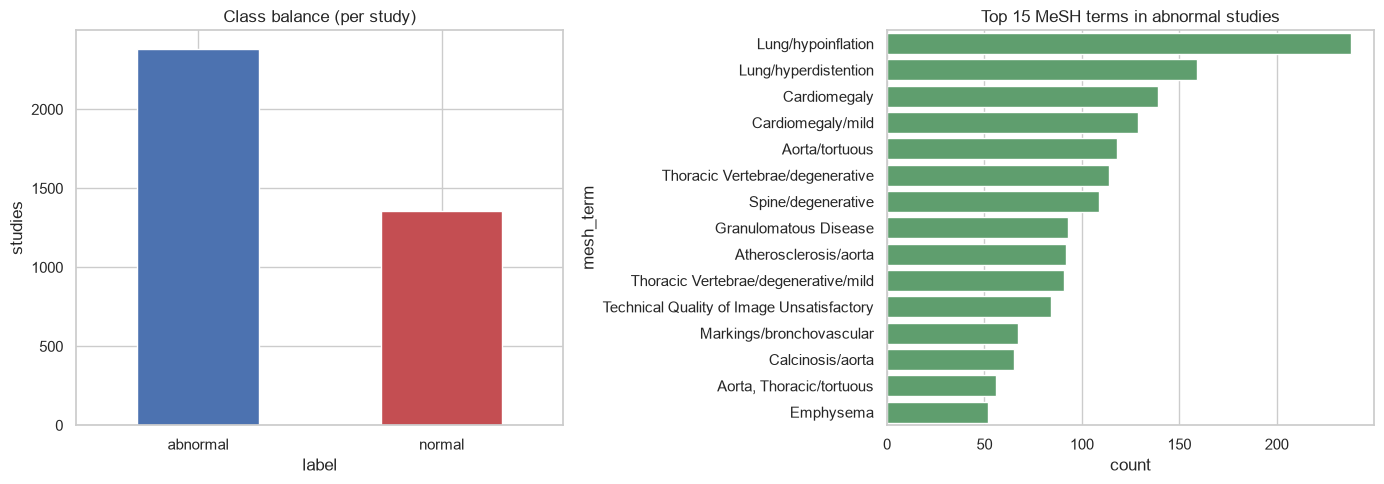

In [4]:
counts = df["label"].value_counts().sort_index()
print(counts.rename({0: "normal", 1: "abnormal"}).to_string())
print((counts / len(df) * 100).round(1).rename({0: "normal %", 1: "abnormal %"}).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
df["label"].map({0: "normal", 1: "abnormal"}).value_counts().plot(kind="bar", color=["#4C72B0", "#C44E52"], rot=0, ax=ax[0])
ax[0].set_title("Class balance (per study)"); ax[0].set_ylabel("studies")

terms = Counter(t.strip() for s in df.loc[df.label == 1, "MeSH"] for t in s.split(";") if t.strip())
top = pd.DataFrame(terms.most_common(15), columns=["mesh_term", "count"])
sns.barplot(data=top, y="mesh_term", x="count", color="#55A868", ax=ax[1])
ax[1].set_title("Top 15 MeSH terms in abnormal studies")
plt.tight_layout(); plt.show()

count    3734.0
mean       44.7
std        22.5
min         4.0
25%        30.0
50%        40.0
75%        54.0
max       257.0
95th percentile: 88 tokens


C:\Users\admin\AppData\Local\Temp\ipykernel_46788\1206171621.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df.assign(cls=df.label.map({0: "normal", 1: "abnormal"})), x="cls", y="n_tokens", ax=ax[1],


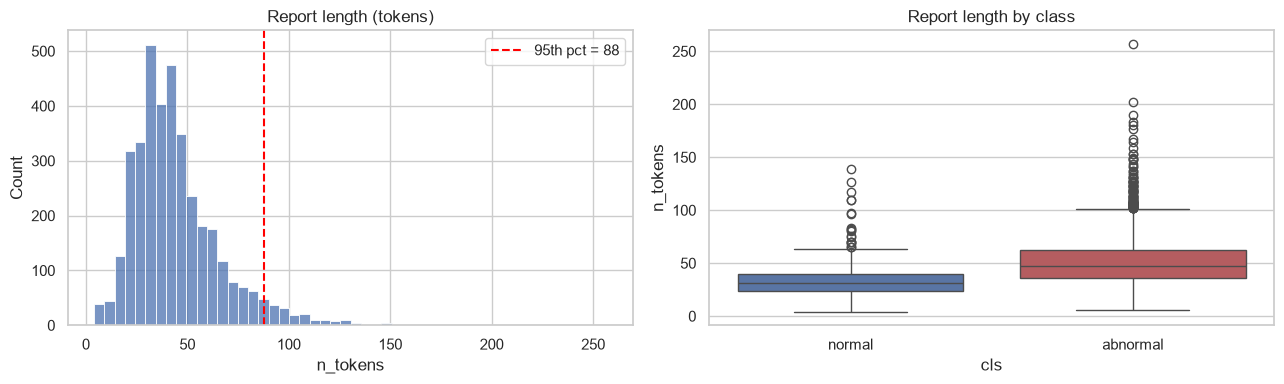

In [5]:
p95 = int(df["n_tokens"].quantile(0.95))
print(df["n_tokens"].describe().round(1).to_string())
print("95th percentile:", p95, "tokens")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["n_tokens"], bins=50, ax=ax[0], color="#4C72B0")
ax[0].axvline(p95, color="red", ls="--", label=f"95th pct = {p95}"); ax[0].legend(); ax[0].set_title("Report length (tokens)")
sns.boxplot(data=df.assign(cls=df.label.map({0: "normal", 1: "abnormal"})), x="cls", y="n_tokens", ax=ax[1],
            palette=["#4C72B0", "#C44E52"])
ax[1].set_title("Report length by class")
plt.tight_layout(); plt.show()

In [6]:
pj = proj.merge(df[["uid", "label"]], on="uid", how="inner")
print(pj["projection"].value_counts().to_string())
print("Images per study:", pj.groupby("uid").size().value_counts().sort_index().to_dict())

smp = pj.sample(min(1000, len(pj)), random_state=SEED)
sizes = []
for p in smp["path"]:
    with Image.open(p) as im:
        sizes.append(im.size)
sizes = pd.DataFrame(sizes, columns=["width", "height"])
print(sizes.describe().round(0).to_string())
print("Most common sizes:", sizes.value_counts().head(3).to_dict())

projection
Frontal    3703
Lateral    3551
Images per study: {1: 417, 2: 3127, 3: 178, 4: 11, 5: 1}
        width  height
count  1000.0  1000.0
mean   2156.0  2222.0
std     190.0   221.0
min    1529.0  1798.0
25%    2048.0  2048.0
50%    2048.0  2048.0
75%    2160.0  2496.0
max    2773.0  3001.0
Most common sizes: {(2048, 2496): 269, (2048, 2048): 188, (2496, 2048): 162}


In [7]:
front = proj[proj["projection"] == "Frontal"].drop_duplicates("uid")[["uid", "path"]]
data = df.merge(front, on="uid", how="inner").sort_values("uid").reset_index(drop=True)
assert data.uid.is_unique, "Expected one report per study UID"
if QUICK_TEST and len(data) > QUICK_N:
    data, _ = train_test_split(data, train_size=min(QUICK_N, len(data)), stratify=data["label"], random_state=SEED)
    data = data.sort_values("uid").reset_index(drop=True)
print("Studies with a frontal image and a report:", len(data))

tr, tmp = train_test_split(data.index, test_size=0.30, stratify=data["label"], random_state=SEED)
va, te = train_test_split(tmp, test_size=0.50, stratify=data.loc[tmp, "label"], random_state=SEED)
data["split"] = "train"
data.loc[va, "split"] = "val"
data.loc[te, "split"] = "test"
IDX = {s: np.where(data["split"].values == s)[0] for s in ["train", "val", "test"]}
Y = data["label"].values
print(data.groupby("split")["label"].agg(studies="size", abnormal_rate="mean").round(3).to_string())

data[["uid","label","split"]].to_csv(Path(RESULTS_DIR) / "study_splits.csv", index=False)
fingerprint = hashlib.sha256(f"iu-v2/{IMG_SIZE}/{SEED}".encode())
for row in data.itertuples():
    file = Path(row.path)
    stat = file.stat()
    fingerprint.update(repr((row.uid, str(file.resolve()), stat.st_size, stat.st_mtime_ns)).encode())
DATA_KEY = fingerprint.hexdigest()[:20]
RESAMPLE = getattr(Image, "Resampling", Image).BICUBIC

def load_gray(path, size):
    with Image.open(path) as im:
        from PIL import ImageOps
        im = ImageOps.exif_transpose(im)
        if im.mode in ("I", "I;16", "I;16L", "I;16B"):
            pixels = np.asarray(im, dtype=np.float32)
            lo, hi = float(pixels.min()), float(pixels.max())
            im = Image.fromarray(((pixels - lo) / max(hi - lo, 1.0) * 255).astype(np.uint8))
        else:
            im = im.convert("L")
        return np.asarray(im.resize((size, size), RESAMPLE, reducing_gap=2.0), dtype=np.uint8)

img_cache = f"{CACHE_DIR}/imgs_{IMG_SIZE}_{DATA_KEY}.npy"
if os.path.exists(img_cache):
    IMGS = np.load(img_cache)
else:
    with ThreadPoolExecutor(max_workers=min(8, os.cpu_count() or 2)) as ex:
        IMGS = np.stack(list(tqdm(ex.map(lambda p: load_gray(p, IMG_SIZE), data["path"]), total=len(data), desc="resizing images")))
    save_array(img_cache, IMGS)
print("Image array:", IMGS.shape, IMGS.dtype)


chunks = []
for i in range(0, len(IMGS), 256):
    t = torch.from_numpy(IMGS[i:i + 256]).float().unsqueeze(1)
    chunks.append(F.interpolate(t, size=CUSTOM_CNN_SIZE, mode="area").round().byte().squeeze(1))
IMGS_SMALL = torch.cat(chunks).numpy()

Studies with a frontal image and a report: 3580
       studies  abnormal_rate
split                        
test       537          0.631
train     2506          0.631
val        537          0.631


resizing images: 100%|██████████| 3580/3580 [01:07<00:00, 52.90it/s]


Image array: (3580, 224, 224) uint8


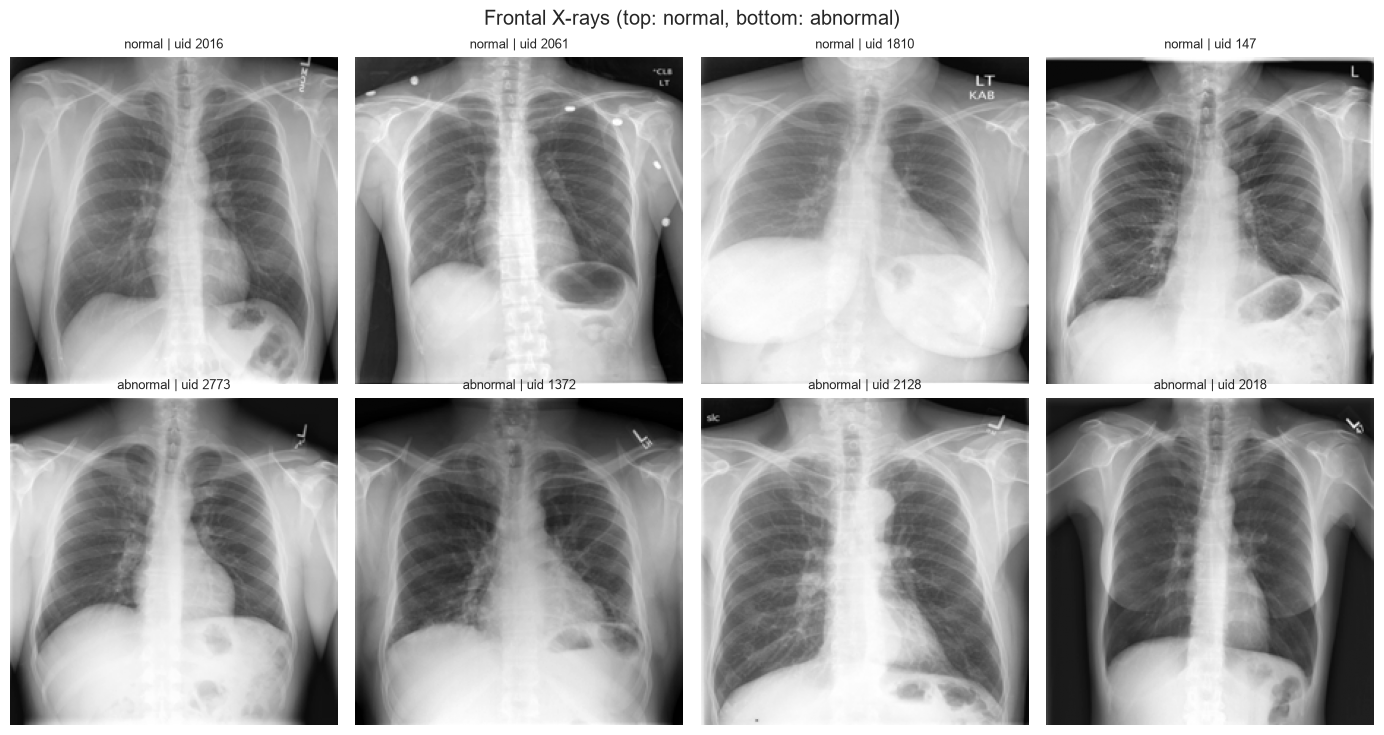

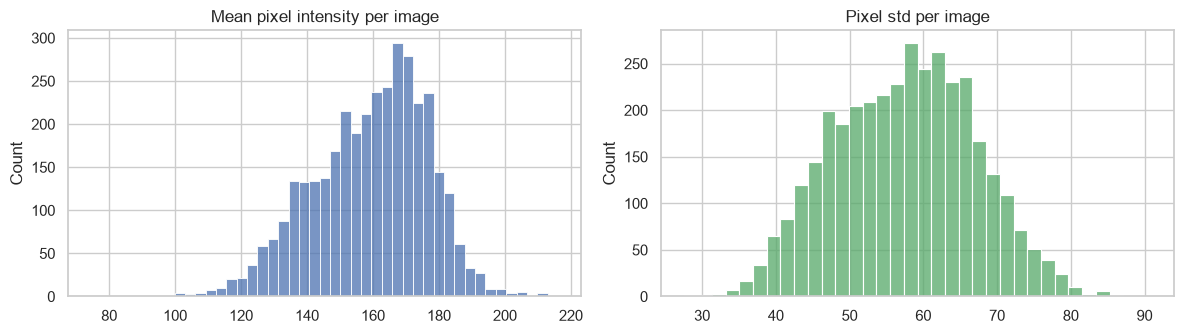

Example report (uid 1 , label 0 ):
 the cardiac silhouette and mediastinum size are within normal limits. there is no pulmonary edema. there is no focal consolidation. there are no of a pleural effusion. there is no evidence of pneumothorax. normal chest x .


In [8]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for r, (lab, name) in enumerate([(0, "normal"), (1, "abnormal")]):
    ids = np.random.RandomState(SEED).choice(np.where(Y == lab)[0], 4, replace=False)
    for c, i in enumerate(ids):
        axes[r, c].imshow(IMGS[i], cmap="gray"); axes[r, c].axis("off")
        axes[r, c].set_title(f"{name} | uid {data.uid[i]}", fontsize=9)
plt.suptitle("Frontal X-rays (top: normal, bottom: abnormal)"); plt.tight_layout(); plt.show()

means, stds = IMGS.reshape(len(IMGS), -1).mean(1), IMGS.reshape(len(IMGS), -1).std(1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(means, ax=ax[0], color="#4C72B0"); ax[0].set_title("Mean pixel intensity per image")
sns.histplot(stds, ax=ax[1], color="#55A868"); ax[1].set_title("Pixel std per image")
plt.tight_layout(); plt.show()

ex = data.iloc[IDX["train"][0]]
print("Example report (uid", ex.uid, ", label", ex.label, "):\n", ex.report)

## 2 · Classical image classifiers
Each feature vector combines oriented gradients, local binary patterns and intensity statistics. Three-fold cross-validation on the training studies selects the SVM and forest parameters by abnormal-class F1.

In [9]:
from skimage.feature import hog, local_binary_pattern

def handcrafted(img):
    im = np.asarray(Image.fromarray(img).resize((128, 128), RESAMPLE))
    h = hog(im, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), feature_vector=True)
    lbp = local_binary_pattern(im, P=8, R=1, method="uniform")
    lbp_hist = []
    for i in range(4):
        for j in range(4):
            patch = lbp[i * 32:(i + 1) * 32, j * 32:(j + 1) * 32]
            lbp_hist.append(np.histogram(patch, bins=10, range=(0, 10))[0] / patch.size)
    inten = np.histogram(im, bins=32, range=(0, 255))[0] / im.size
    stats = np.array([im.mean(), im.std(), *np.percentile(im, [5, 25, 50, 75, 95])]) / 255.0
    return np.concatenate([h, np.concatenate(lbp_hist), inten, stats]).astype(np.float32)

hc_path = f"{CACHE_DIR}/handcrafted_{DATA_KEY}.npy"
if os.path.exists(hc_path):
    XH = np.load(hc_path)
else:
    XH = np.stack([handcrafted(im) for im in tqdm(IMGS, desc="HOG + LBP + intensity")])
    save_array(hc_path, XH)
print("Hand-crafted feature matrix:", XH.shape)

HOG + LBP + intensity: 100%|██████████| 3580/3580 [00:30<00:00, 116.69it/s]

Hand-crafted feature matrix: (3580, 1963)


In [10]:
CLS_PATH = f"{RESULTS_DIR}/cls_results.json"
CLS = load_json(CLS_PATH, {})

def cls_eval(y, pred, score):
    return dict(accuracy=float(accuracy_score(y, pred)),
                precision=float(precision_score(y, pred, zero_division=0)),
                recall=float(recall_score(y, pred, zero_division=0)),
                f1=float(f1_score(y, pred, zero_division=0)),
                auc=float(roc_auc_score(y, score)) if len(set(y)) > 1 else float("nan"))

def record_cls(name, group, val, test, extra=None):
    CLS[name] = {"group": group, "val": val, "test": test, **(extra or {})}
    save_json(CLS_PATH, CLS)

def fit_sklearn(name, gs, X):
    t0 = time.time()
    gs.fit(X[IDX["train"]], Y[IDX["train"]])
    est, out, scores = gs.best_estimator_, {}, {}
    for sp in ["val", "test"]:
        i = IDX[sp]
        s = est.decision_function(X[i]) if hasattr(est, "decision_function") else est.predict_proba(X[i])[:, 1]
        out[sp], scores[sp] = cls_eval(Y[i], est.predict(X[i]), s), s
    print(f"{name}: best params {gs.best_params_} | CV f1 {gs.best_score_:.3f} | {time.time() - t0:.0f}s")
    print("  val :", {k: round(v, 3) for k, v in out["val"].items()})
    print("  test:", {k: round(v, 3) for k, v in out["test"].items()})
    return est, out, scores

svm_gs = GridSearchCV(Pipeline([("sc", StandardScaler()), ("clf", SVC(kernel="rbf", class_weight="balanced"))]),
                      {"clf__C": [0.5, 2, 8], "clf__gamma": ["scale", 1e-4]}, cv=3, scoring="f1", n_jobs=2)
rf_gs = GridSearchCV(RandomForestClassifier(class_weight="balanced_subsample", random_state=SEED, n_jobs=2),
                     {"n_estimators": [200, 500], "max_depth": [None, 20], "min_samples_leaf": [1, 3]},
                     cv=3, scoring="f1", n_jobs=1)

if QUICK_TEST:
    svm_gs.param_grid = {"clf__C": [2], "clf__gamma": ["scale"]}
    rf_gs.param_grid = {"n_estimators": [40], "max_depth": [12]}
svm_est, svm_res, svm_scores = fit_sklearn("SVM (RBF)", svm_gs, XH)
rf_est, rf_res, rf_scores = fit_sklearn("Random Forest", rf_gs, XH)
record_cls("svm", "Classical ML (HOG+LBP)", svm_res["val"], svm_res["test"])
record_cls("rf", "Classical ML (HOG+LBP)", rf_res["val"], rf_res["test"])

SVM (RBF): best params {'clf__C': 8, 'clf__gamma': 'scale'} | CV f1 0.776 | 91s
  val : {'accuracy': 0.669, 'precision': 0.712, 'recall': 0.796, 'f1': 0.752, 'auc': 0.73}
  test: {'accuracy': 0.683, 'precision': 0.716, 'recall': 0.826, 'f1': 0.767, 'auc': 0.715}
Random Forest: best params {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 500} | CV f1 0.783 | 258s
  val : {'accuracy': 0.661, 'precision': 0.671, 'recall': 0.909, 'f1': 0.772, 'auc': 0.738}
  test: {'accuracy': 0.667, 'precision': 0.673, 'recall': 0.917, 'f1': 0.777, 'auc': 0.721}


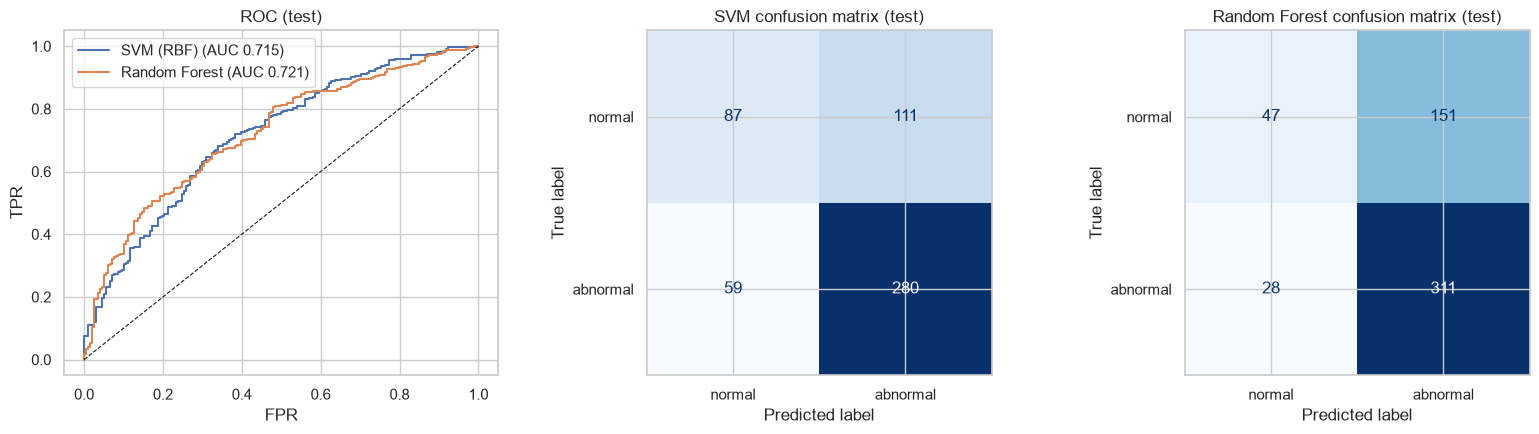

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for name, sc in [("SVM (RBF)", svm_scores["test"]), ("Random Forest", rf_scores["test"])]:
    fpr, tpr, _ = roc_curve(Y[IDX["test"]], sc)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(Y[IDX['test']], sc):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set_title("ROC (test)"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend()
for a, (name, est) in zip(ax[1:], [("SVM", svm_est), ("Random Forest", rf_est)]):
    ConfusionMatrixDisplay(confusion_matrix(Y[IDX["test"]], est.predict(XH[IDX["test"]])),
                           display_labels=["normal", "abnormal"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{name} confusion matrix (test)")
plt.tight_layout(); plt.show()

## 3 · Fixed and tuned ANNs
ResNet-50 and DenseNet-121 each produce a frozen image embedding. Fit the scaler on training data. Compare fixed ANN heads on validation accuracy, then run a seeded random search on the selected backbone. Each trial varies hidden layers, dropout, optimizer, batch size and learning rate. The first trial repeats the fixed configuration so it remains eligible for selection.

In [12]:
def build_backbone(name, pretrained=True):
    W = (lambda w: w.DEFAULT) if pretrained else (lambda w: None)
    if name == "resnet50":
        m = models.resnet50(weights=W(models.ResNet50_Weights)); m.fc = nn.Identity()
    elif name == "vgg16":
        v = models.vgg16(weights=W(models.VGG16_Weights)); m = nn.Sequential(v.features, nn.AdaptiveAvgPool2d(1), nn.Flatten())
    elif name == "densenet121":
        m = models.densenet121(weights=W(models.DenseNet121_Weights)); m.classifier = nn.Identity()
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=W(models.EfficientNet_B0_Weights)); m.classifier = nn.Identity()
    else:
        raise ValueError(name)
    return m

class CustomCNN(nn.Module):
    def __init__(self, widths=(32, 64, 128, 256, 512), convs=(2, 2, 2, 2, 2)):
        super().__init__()
        layers, in_ch = [], 1
        for w, n in zip(widths, convs):
            for _ in range(n):
                layers += [nn.Conv2d(in_ch, w, 3, padding=1, bias=False), nn.BatchNorm2d(w), nn.ReLU(inplace=True)]
                in_ch = w
            layers.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.out_dim = widths[-1]
    def forward(self, x):
        return self.pool(self.features(x)).flatten(1)

def layer_table(container, x, leaf=False):

    rows, hooks = [], []
    for n, m in container.named_modules():
        if n == "":
            continue
        is_leaf = len(list(m.children())) == 0
        if (leaf and is_leaf) or (not leaf and "." not in n):
            hooks.append(m.register_forward_hook(
                lambda mod, i, o, n=n: rows.append({"layer": n, "type": mod.__class__.__name__,
                                                    "output shape (C,H,W)": tuple(o.shape[1:]) if torch.is_tensor(o) else "-",
                                                    "params": sum(p.numel() for p in mod.parameters())})))
    container.eval()
    with torch.no_grad():
        container(x)
    for h in hooks:
        h.remove()
    return pd.DataFrame(rows)

TYPE_NOTES = {"Conv2d": "learnable 3x3 filters (feature detectors)", "BatchNorm2d": "normalise channel activations",
              "ReLU": "non-linearity: max(0, x)", "MaxPool2d": "halve height and width, keep strongest responses",
              "AdaptiveAvgPool2d": "global average pooling -> one value per channel", "Flatten": "reshape to a vector"}
cnn_demo = CustomCNN()
t = layer_table(cnn_demo.features, torch.zeros(1, 1, CUSTOM_CNN_SIZE, CUSTOM_CNN_SIZE), leaf=True)
t["what it does"] = t["type"].map(TYPE_NOTES)
display(t)
print("Custom CNN parameters:", f"{sum(p.numel() for p in cnn_demo.parameters()):,}", "| output vector size:", cnn_demo.out_dim)

,layer,type,"output shape (C,H,W)",params,what it does
0,0,Conv2d,"(32, 128, 128)",288,learnable 3x3 filters (feature detectors)
1,1,BatchNorm2d,"(32, 128, 128)",64,normalise channel activations
2,2,ReLU,"(32, 128, 128)",0,"non-linearity: max(0, x)"
3,3,Conv2d,"(32, 128, 128)",9216,learnable 3x3 filters (feature detectors)
4,4,BatchNorm2d,"(32, 128, 128)",64,normalise channel activations
5,5,ReLU,"(32, 128, 128)",0,"non-linearity: max(0, x)"
6,6,MaxPool2d,"(32, 64, 64)",0,"halve height and width, keep strongest responses"
7,7,Conv2d,"(64, 64, 64)",18432,learnable 3x3 filters (feature detectors)
8,8,BatchNorm2d,"(64, 64, 64)",128,normalise channel activations
9,9,ReLU,"(64, 64, 64)",0,"non-linearity: max(0, x)"


Custom CNN parameters: 4,713,632 | output vector size: 512


In [13]:
FEATS = {}
def extract_features(name):
    path = f"{CACHE_DIR}/feat_{name}_pt{int(PRETRAINED)}_{DATA_KEY}.npy"
    if os.path.exists(path):
        return np.load(path)
    net = build_backbone(name, PRETRAINED).to(DEVICE).eval()
    mean = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
    bs, out = (64 if DEVICE.type == "cuda" else 16), []
    with torch.no_grad():
        for i in tqdm(range(0, len(IMGS), bs), desc=f"features: {name}"):
            x = torch.from_numpy(IMGS[i:i + bs]).to(DEVICE).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
            out.append(net((x - mean) / std).float().cpu())
    f = torch.cat(out).numpy()
    save_array(path, f)
    del net
    return f

for name in BACKBONES:
    FEATS[name] = extract_features(name)
    print(name, FEATS[name].shape)

features: resnet50: 100%|██████████| 224/224 [07:02<00:00,  1.88s/it]


resnet50 (3580, 2048)


features: densenet121: 100%|██████████| 224/224 [06:12<00:00,  1.66s/it]

densenet121 (3580, 1024)


In [14]:
ACTS = {"relu": nn.ReLU, "gelu": nn.GELU, "leaky_relu": nn.LeakyReLU}

class ANN(nn.Module):
    def __init__(self, in_dim, hidden, dropout, act, bn):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h)] + ([nn.BatchNorm1d(h)] if bn else []) + [ACTS[act](), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(1)

def train_ann(cfg, Xtr, ytr, Xva, yva, max_epochs=100, patience=10, seed=SEED):
    torch.manual_seed(seed)
    model = ANN(Xtr.shape[1], cfg["hidden"], cfg["dropout"], cfg["act"], cfg["bn"]).to(DEVICE)
    if cfg["opt"] == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    elif cfg["opt"] == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    else:
        opt = torch.optim.SGD(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"], momentum=0.9)
    lossf = nn.BCEWithLogitsLoss(pos_weight=(ytr == 0).sum() / ytr.sum().clamp(min=1))
    best_loss, best_state, bad = 1e9, None, 0
    hist = {"train": [], "val": [], "val_acc": []}
    n = len(Xtr)
    for ep in range(max_epochs):
        model.train(); perm = torch.randperm(n, device=DEVICE); tot = 0.0
        for i in range(0, n, cfg["batch"]):
            b = perm[i:i + cfg["batch"]]
            if len(b) < 2:
                continue
            loss = lossf(model(Xtr[b]), ytr[b]); opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            lv = model(Xva); vloss = lossf(lv, yva).item(); vacc = ((lv > 0).float() == yva).float().mean().item()
        hist["train"].append(tot / n); hist["val"].append(vloss); hist["val_acc"].append(vacc)
        if vloss < best_loss - 1e-4:
            best_loss, bad, best_state = vloss, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        prob = torch.sigmoid(model(Xva)).cpu().numpy()
    yv = yva.cpu().numpy().astype(int)
    stats = cls_eval(yv, (prob > 0.5).astype(int), prob)
    stats.update(epochs=ep + 1)
    return model, stats, hist

def ann_predict(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(X)).cpu().numpy()


ANN_X = {}
for name in BACKBONES:
    sc = StandardScaler().fit(FEATS[name][IDX["train"]])
    ANN_X[name] = {sp: torch.tensor(sc.transform(FEATS[name][IDX[sp]]), dtype=torch.float32, device=DEVICE) for sp in IDX}
ANN_Y = {sp: torch.tensor(Y[IDX[sp]], dtype=torch.float32, device=DEVICE) for sp in IDX}

BASE_CFG = dict(hidden=[128, 64], dropout=0.3, act="relu", bn=True, opt="adam", lr=1e-3, wd=1e-4, batch=64)
base_val = {}
for name in BACKBONES:
    model, st, _ = train_ann(BASE_CFG, ANN_X[name]["train"], ANN_Y["train"], ANN_X[name]["val"], ANN_Y["val"])
    p = ann_predict(model, ANN_X[name]["test"])
    test = cls_eval(Y[IDX["test"]], (p > 0.5).astype(int), p)
    val = {k: v for k, v in st.items() if k != "epochs"}
    record_cls(f"ann_base_{name}", "ANN (untuned, deep features)", val, test, {"backbone": name})
    base_val[name] = val["accuracy"]
    print(f"{name:16s} untuned ANN | val acc {val['accuracy']:.3f} | test acc {test['accuracy']:.3f} | test F1 {test['f1']:.3f} | test AUC {test['auc']:.3f}")

BEST_BB = max(base_val, key=base_val.get)
print("\nBest backbone by validation accuracy:", BEST_BB)

resnet50         untuned ANN | val acc 0.682 | test acc 0.685 | test F1 0.734 | test AUC 0.764
densenet121      untuned ANN | val acc 0.680 | test acc 0.700 | test F1 0.744 | test AUC 0.763

Best backbone by validation accuracy: resnet50


In [15]:
def sample_cfg(rng):
    n_layers = int(rng.choice([1, 2, 3])); width = int(rng.choice([64, 128, 256, 512, 1024]))
    return dict(hidden=[max(width // (2 ** i), 16) for i in range(n_layers)],
                dropout=float(rng.uniform(0.1, 0.6)), act=str(rng.choice(list(ACTS))), bn=bool(rng.choice([True, False])),
                opt=str(rng.choice(["adam", "adamw", "sgd"])), lr=float(10 ** rng.uniform(-4, -2)),
                wd=float(10 ** rng.uniform(-6, -2)), batch=int(rng.choice([32, 64, 128])))

rng = np.random.RandomState(SEED)
Xs, ys = ANN_X[BEST_BB], ANN_Y
trials, best = [], {"acc": -1}
for t in tqdm(range(ANN_TRIALS), desc="random search"):
    cfg = BASE_CFG.copy() if t == 0 else sample_cfg(rng)
    model, st, hist = train_ann(cfg, Xs["train"], ys["train"], Xs["val"], ys["val"])
    trials.append({"trial": t, **{k: (str(v) if k == "hidden" else v) for k, v in cfg.items()},
                   "n_layers": len(cfg["hidden"]), "val_acc": st["accuracy"], "val_f1": st["f1"], "val_auc": st["auc"], "epochs": st["epochs"]})
    if st["accuracy"] > best["acc"]:
        best = {"acc": st["accuracy"], "cfg": cfg, "model": model, "hist": hist}

T = pd.DataFrame(trials).sort_values("val_acc", ascending=False).reset_index(drop=True)
print("Top 5 configurations:")
display(T.head(5).round(4))
print("Best configuration:", best["cfg"])

random search: 100%|██████████| 12/12 [00:48<00:00,  4.07s/it]

Top 5 configurations:


,trial,hidden,dropout,act,bn,opt,lr,wd,batch,n_layers,val_acc,val_f1,val_auc,epochs
0,9,"[512, 256]",0.1226,relu,False,adam,0.0003,0.0021,64,2,0.6927,0.7426,0.7712,11
1,4,"[128, 64, 32]",0.1233,leaky_relu,False,adamw,0.0037,0.0000,128,3,0.6853,0.7363,0.7522,11
2,0,"[128, 64]",0.3000,relu,True,adam,0.0010,0.0001,64,2,0.6816,0.7299,0.7535,12
3,11,[64],0.1994,leaky_relu,True,sgd,0.0026,0.0008,32,1,0.6778,0.7205,0.7547,12
4,10,[512],0.4035,relu,True,adam,0.0040,0.0000,128,1,0.6760,0.7194,0.7679,12


Best configuration: {'hidden': [512, 256], 'dropout': 0.12261364445526904, 'act': 'relu', 'bn': False, 'opt': 'adam', 'lr': 0.00034889766548903636, 'wd': 0.002065142557895924, 'batch': 64}


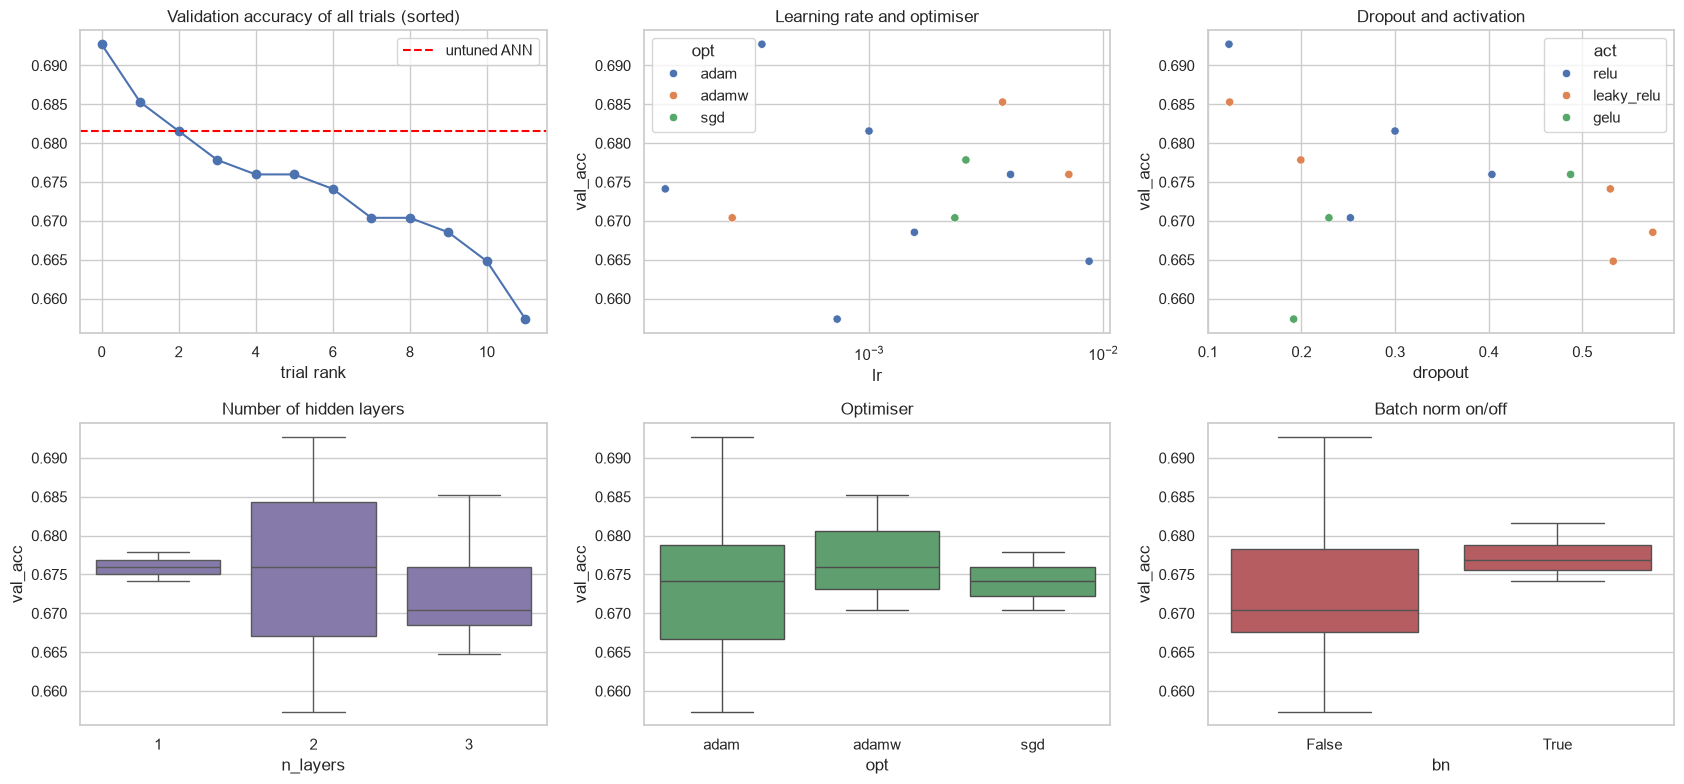

In [16]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
ax[0, 0].plot(np.sort(T["val_acc"].values)[::-1], "o-"); ax[0, 0].axhline(base_val[BEST_BB], color="red", ls="--", label="untuned ANN")
ax[0, 0].set_title("Validation accuracy of all trials (sorted)"); ax[0, 0].set_xlabel("trial rank"); ax[0, 0].legend()
sns.scatterplot(data=T, x="lr", y="val_acc", hue="opt", ax=ax[0, 1]); ax[0, 1].set_xscale("log"); ax[0, 1].set_title("Learning rate and optimiser")
sns.scatterplot(data=T, x="dropout", y="val_acc", hue="act", ax=ax[0, 2]); ax[0, 2].set_title("Dropout and activation")
sns.boxplot(data=T, x="n_layers", y="val_acc", ax=ax[1, 0], color="#8172B2"); ax[1, 0].set_title("Number of hidden layers")
sns.boxplot(data=T, x="opt", y="val_acc", ax=ax[1, 1], color="#55A868"); ax[1, 1].set_title("Optimiser")
sns.boxplot(data=T, x="bn", y="val_acc", ax=ax[1, 2], color="#C44E52"); ax[1, 2].set_title("Batch norm on/off")
plt.tight_layout(); plt.show()

Tuned ANN on resnet50 features
  val : {'accuracy': 0.693, 'precision': 0.788, 'recall': 0.702, 'f1': 0.743, 'auc': 0.771}
  test: {'accuracy': 0.687, 'precision': 0.775, 'recall': 0.711, 'f1': 0.742, 'auc': 0.763}
  test accuracy: untuned 0.685  ->  tuned 0.687


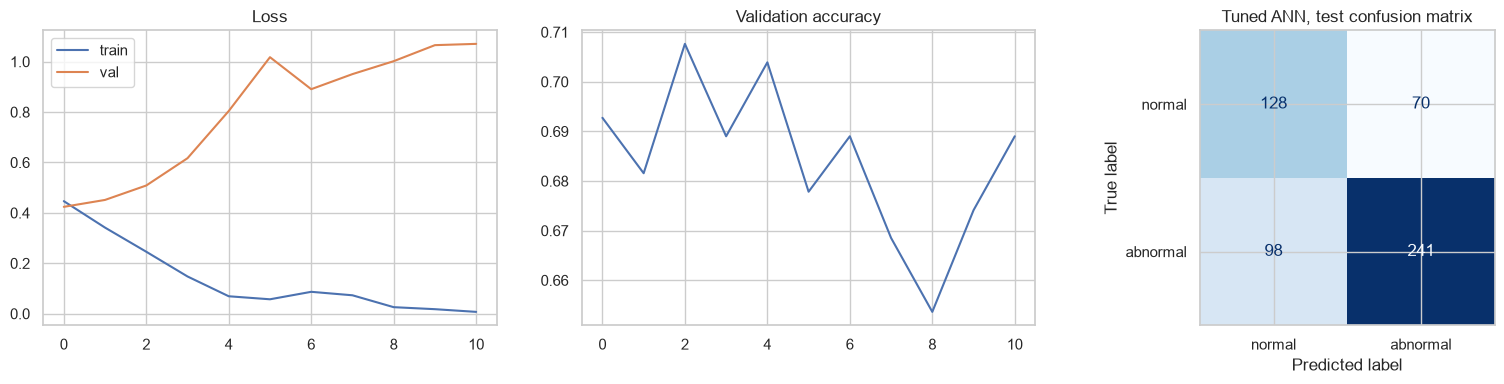

In [17]:
model = best["model"]
pv_, pt_ = ann_predict(model, Xs["val"]), ann_predict(model, Xs["test"])
val = cls_eval(Y[IDX["val"]], (pv_ > 0.5).astype(int), pv_)
test = cls_eval(Y[IDX["test"]], (pt_ > 0.5).astype(int), pt_)
record_cls("ann_tuned", "ANN (tuned, deep features)", val, test, {"backbone": BEST_BB, "config": best["cfg"]})
print(f"Tuned ANN on {BEST_BB} features")
print("  val :", {k: round(v, 3) for k, v in val.items()})
print("  test:", {k: round(v, 3) for k, v in test.items()})
print(f"  test accuracy: untuned {CLS[f'ann_base_{BEST_BB}']['test']['accuracy']:.3f}  ->  tuned {test['accuracy']:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(best["hist"]["train"], label="train"); ax[0].plot(best["hist"]["val"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(best["hist"]["val_acc"]); ax[1].set_title("Validation accuracy")
ConfusionMatrixDisplay(confusion_matrix(Y[IDX["test"]], (pt_ > 0.5).astype(int)), display_labels=["normal", "abnormal"]).plot(ax=ax[2], colorbar=False, cmap="Blues")
ax[2].set_title("Tuned ANN, test confusion matrix")
plt.tight_layout(); plt.show()

In [18]:
T.to_csv(Path(RESULTS_DIR) / "ann_trials.csv", index=False)

## 4 · CNN depth and CNN–LSTM generation
First compare two CNNs on the same classification task. Both learn directly from pixels, with two convolutions per block. Keep widths, optimizer and augmentation consistent in the shared blocks. Then train image-to-text models using the same study split. The report vocabulary and length cap come from training text.

In [19]:
PAD, SOS, EOS, UNK = 0, 1, 2, 3
data["tokens"] = data["report"].apply(tok)

train_counts = Counter(w for t in data.loc[data.split == "train", "tokens"] for w in t)
itos = ["<pad>", "<sos>", "<eos>", "<unk>"] + sorted(w for w, c in train_counts.items() if c >= MIN_WORD_FREQ)
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)

train_lens = data.loc[data.split == "train", "tokens"].apply(len)
MAX_TOK = int(min(np.percentile(train_lens, 95), MAX_TOKENS_CAP))
print(f"Vocabulary size (train, freq >= {MIN_WORD_FREQ}): {V} | max report length used: {MAX_TOK} tokens (95th percentile, capped at {MAX_TOKENS_CAP})")

def encode(tokens):
    ids = [SOS] + [stoi.get(w, UNK) for w in tokens[:MAX_TOK]] + [EOS]
    return ids + [PAD] * (MAX_TOK + 2 - len(ids))

CAPS = torch.tensor([encode(t) for t in data["tokens"]], dtype=torch.long, device=DEVICE)

def detok(s):
    return re.sub(r"\s+([.,])", r"\1", s)

def decode(ids):
    out = []
    for i in ids:
        if i == EOS:
            break
        if i in (PAD, SOS):
            continue
        out.append(itos[i])
    return detok(" ".join(out))

print("Example encoding:", CAPS[0][:12].tolist(), "->", decode(CAPS[0].tolist())[:80], "...")

Vocabulary size (train, freq >= 3): 1007 | max report length used: 85 tokens (95th percentile, capped at 100)
Example encoding: [1, 915, 163, 836, 62, 578, 840, 83, 999, 617, 533, 5] -> the cardiac silhouette and mediastinum size are within normal limits. there is n ...


**Report baselines and metrics.** A constant training report and the report of the nearest training image show how much overlap a simple method can achieve. Corpus BLEU-1 through BLEU-4 and mean ROUGE-L measure agreement with one reference. Label-Acc and Label-F1 come from an auxiliary text classifier trained on reference reports. These proxy scores cannot verify individual findings, negation or anatomical location. Distinct is the fraction of unique generated texts.

In [20]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction


tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
text_clf = LogisticRegression(max_iter=2000, class_weight="balanced")
text_clf.fit(tfidf.fit_transform(data.loc[IDX["train"], "report"]), Y[IDX["train"]])

def label_from_text(texts):
    return text_clf.predict(tfidf.transform(list(texts)))

ceiling = accuracy_score(Y[IDX["val"]], label_from_text(data.loc[IDX["val"], "report"]))
print(f"Text classifier accuracy on real validation reports (reference-text check): {ceiling:.3f}")

def bleu_scores(refs_t, hyps_t):
    smooth = SmoothingFunction().method1
    r = [[x] for x in refs_t]
    return {f"BLEU-{n}": float(corpus_bleu(r, hyps_t, weights=tuple([1 / n] * n), smoothing_function=smooth)) for n in range(1, 5)}

def lcs_len(a, b):
    prev = [0] * (len(b) + 1)
    for x in a:
        cur = [0]
        for j, y in enumerate(b):
            cur.append(prev[j] + 1 if x == y else max(prev[j + 1], cur[j]))
        prev = cur
    return prev[-1]

def rouge_l(ref, hyp):
    if not ref or not hyp:
        return 0.0
    l = lcs_len(ref, hyp)
    if l == 0:
        return 0.0
    p, r = l / len(hyp), l / len(ref)
    return 2 * p * r / (p + r)

_REF = data.set_index("uid")["report"]
_LAB = data.set_index("uid")["label"]
TEST_UIDS = data["uid"].values[IDX["test"]]

def evaluate_generation(name, uids, hyps, save=True):
    refs = [_REF[u] for u in uids]
    y = np.array([_LAB[u] for u in uids])
    refs_t = [tok(r) for r in refs]
    hyps_t = [tok(h) or ["<empty>"] for h in hyps]
    m = bleu_scores(refs_t, hyps_t)
    m["ROUGE-L"] = float(np.mean([rouge_l(r, h) for r, h in zip(refs_t, hyps_t)]))
    pred = label_from_text(hyps)
    m["Label-Acc"] = float(accuracy_score(y, pred))
    m["Label-F1"] = float(f1_score(y, pred, zero_division=0))
    m["Macro-F1"] = float(f1_score(y, pred, labels=[0,1], average="macro", zero_division=0))
    m["UniqueReports"] = len(set(hyps))
    m["AvgLen"] = float(np.mean([len(h) for h in hyps_t]))
    m["Distinct"] = len(set(hyps)) / len(hyps)
    if save:
        pd.DataFrame({"uid": uids, "reference": refs, "generated": hyps}).to_csv(f"{RESULTS_DIR}/preds_{name}.csv", index=False)
    return m

META_PATH = f"{RESULTS_DIR}/gen_meta.json"
GEN_META = load_json(META_PATH, {})
def show_metrics(name, m):
    print(name, "->", {k: round(v, 4) for k, v in m.items()})

Text classifier accuracy on real validation reports (reference-text check): 0.937


In [21]:
most_common_report = data.loc[data.split == "train", "report"].value_counts().index[0]
print("Constant report:", most_common_report[:200])
m = evaluate_generation("baseline_constant", TEST_UIDS, [most_common_report] * len(TEST_UIDS))
show_metrics("baseline_constant", m)

Constant report: the heart is normal in size. the mediastinum is unremarkable. the lungs are clear. no acute disease.
baseline_constant -> {'BLEU-1': 0.1821, 'BLEU-2': 0.1152, 'BLEU-3': 0.0789, 'BLEU-4': 0.0566, 'ROUGE-L': 0.328, 'Label-Acc': 0.3687, 'Label-F1': 0.0, 'Macro-F1': 0.2694, 'UniqueReports': 1, 'AvgLen': 21.0, 'Distinct': 0.0019}


In [22]:
bb = BACKBONES[0]
fz = StandardScaler().fit(FEATS[bb][IDX["train"]])
Z = fz.transform(FEATS[bb]); Z /= (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-8)
nn_idx = (Z[IDX["test"]] @ Z[IDX["train"]].T).argmax(1)
knn_hyps = data["report"].values[IDX["train"]][nn_idx].tolist()
m = evaluate_generation("baseline_knn", TEST_UIDS, knn_hyps)
show_metrics(f"baseline_knn ({bb} features)", m)

baseline_knn (resnet50 features) -> {'BLEU-1': 0.3606, 'BLEU-2': 0.2177, 'BLEU-3': 0.1414, 'BLEU-4': 0.0968, 'ROUGE-L': 0.2937, 'Label-Acc': 0.5866, 'Label-F1': 0.6442, 'Macro-F1': 0.5754, 'UniqueReports': 361, 'AvgLen': 42.311, 'Distinct': 0.6723}


In [23]:
class LSTMDecoder(nn.Module):
    def __init__(self, feat_dim, vocab_size, embed=EMBED, hidden=HIDDEN, layers=LSTM_LAYERS, dropout=DROPOUT):
        super().__init__()
        self.L, self.H = layers, hidden
        self.norm = nn.LayerNorm(feat_dim)
        self.feat_drop = nn.Dropout(dropout)
        self.init_h = nn.Linear(feat_dim, hidden * layers)
        self.init_c = nn.Linear(feat_dim, hidden * layers)
        self.embed = nn.Embedding(vocab_size, embed, padding_idx=PAD)
        self.lstm = nn.LSTM(embed, hidden, layers, batch_first=True, dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, vocab_size)

    def init_state(self, feat):
        f = self.feat_drop(self.norm(feat))
        h = torch.tanh(self.init_h(f)).view(-1, self.L, self.H).transpose(0, 1).contiguous()
        c = torch.tanh(self.init_c(f)).view(-1, self.L, self.H).transpose(0, 1).contiguous()
        return h, c

    def forward(self, feat, caps_in):
        out, _ = self.lstm(self.drop(self.embed(caps_in)), self.init_state(feat))
        return self.fc(self.drop(out))

    def step(self, tok_ids, state):
        out, state = self.lstm(self.embed(tok_ids).unsqueeze(1), state)
        return self.fc(out.squeeze(1)), state

class Captioner(nn.Module):
    def __init__(self, encoder, feat_dim, vocab_size):
        super().__init__()
        self.encoder = encoder
        self.decoder = LSTMDecoder(feat_dim, vocab_size)
    def encode(self, x):
        return self.encoder(x)
    def forward(self, x, caps_in):
        return self.decoder(self.encode(x), caps_in)


def prep_feat(x, train):
    return x.float()

def augment(x):

    B, dev = x.size(0), x.device
    ang = (torch.rand(B, device=dev) - 0.5) * 2 * math.radians(5)
    sc = 1 + (torch.rand(B, device=dev) - 0.5) * 0.1
    tx, ty = (torch.rand(B, device=dev) - 0.5) * 0.1, (torch.rand(B, device=dev) - 0.5) * 0.1
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, list(x.shape), align_corners=False), padding_mode="border", align_corners=False)
    b = (torch.rand(B, 1, 1, 1, device=dev) - 0.5) * 0.2
    c = 1 + (torch.rand(B, 1, 1, 1, device=dev) - 0.5) * 0.2
    return ((x - 0.5) * c + 0.5 + b).clamp(0, 1)

_tr_pix = IMGS_SMALL[IDX["train"]].astype(np.float32) / 255.0
IMG_MEAN, IMG_STD = float(_tr_pix.mean()), float(_tr_pix.std())
def prep_img(x, train):
    x = x.float().div(255).unsqueeze(1)
    if train:
        x = augment(x)
    return (x - IMG_MEAN) / IMG_STD


def token_loss(logits, target):
    return F.cross_entropy(logits.reshape(-1, V), target.reshape(-1), ignore_index=PAD, reduction="sum")

def as_idx(a):
    return torch.as_tensor(np.asarray(a), device=DEVICE, dtype=torch.long)

@torch.no_grad()
def eval_loss(model, X, prep, idx, batch):
    model.eval(); tot, n = 0.0, 0
    for i in range(0, len(idx), batch):
        b = as_idx(idx[i:i + batch]); c = CAPS[b]
        tot += token_loss(model(prep(X[b], False), c[:, :-1]), c[:, 1:]).item()
        n += (c[:, 1:] != PAD).sum().item()
    return tot / n

def train_captioner(name, model, X, prep, epochs, lr, batch, patience=6):
    model.to(DEVICE)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    best, best_state, bad, hist = 1e9, None, 0, {"train": [], "val": []}
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(IDX["train"]); tot, n = 0.0, 0
        for i in range(0, len(perm), batch):
            b = as_idx(perm[i:i + batch])
            if len(b) < 2:
                continue
            c = CAPS[b]
            loss = token_loss(model(prep(X[b], True), c[:, :-1]), c[:, 1:])
            ntok = (c[:, 1:] != PAD).sum()
            opt.zero_grad(); (loss / ntok).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
            tot += loss.item(); n += ntok.item()
        v = eval_loss(model, X, prep, IDX["val"], batch)
        hist["train"].append(tot / n); hist["val"].append(v); sched.step(v)
        print(f"  [{name}] epoch {ep + 1:02d}/{epochs} | train loss {tot / n:.3f} | val loss {v:.3f} | val ppl {math.exp(v):.1f}")
        if v < best - 1e-4:
            best, bad, best_state = v, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience:
                print("  early stopping"); break
    model.load_state_dict(best_state)
    return hist


BAN = [PAD, SOS, UNK]

def repeats_ngram(seq, nxt, n=NO_REPEAT_NGRAM):
    if n <= 0 or len(seq) < n - 1:
        return False
    cand = tuple(seq[-(n - 1):] + [nxt])
    return any(tuple(seq[i:i + n]) == cand for i in range(len(seq) - n + 1))

@torch.no_grad()
def beam_search(dec, feat1, beam, max_len):
    beams = [(0.0, [SOS], dec.init_state(feat1), False)]
    for _ in range(max_len):
        cand = []
        for score, seq, state, done in beams:
            if done:
                cand.append((score, seq, state, True)); continue
            logits, new_state = dec.step(torch.tensor([seq[-1]], device=feat1.device), state)
            logp = F.log_softmax(logits, -1)[0]
            logp[BAN] = -1e9
            top_lp, top_id = logp.topk(min(beam * 3, logp.numel()))
            kept = 0
            for lp, i in zip(top_lp.tolist(), top_id.tolist()):
                if i != EOS and repeats_ngram(seq, i):
                    continue
                cand.append((score + lp, seq + [i], new_state, i == EOS)); kept += 1
                if kept == beam:
                    break
            if kept == 0:
                cand.append((score - 1e3, seq + [EOS], new_state, True))
        cand.sort(key=lambda b: b[0] / len(b[1]), reverse=True)
        beams = cand[:beam]
        if all(b[3] for b in beams):
            break
    return max(beams, key=lambda b: b[0] / len(b[1]))[1]

@torch.no_grad()
def generate_texts(model, X, prep, idx, beam=BEAM_SIZE, batch=64):
    model.eval(); outs = []
    for i in range(0, len(idx), batch):
        b = as_idx(idx[i:i + batch]); feat = model.encode(prep(X[b], False))
        outs += [decode(beam_search(model.decoder, feat[j:j + 1], beam, MAX_TOK + 1)) for j in range(len(b))]
    return outs

HISTS = {}
def run_captioner(name, encoder, feat_dim, X, prep, epochs, lr, batch):
    set_seed()
    model = Captioner(encoder, feat_dim, V).to(DEVICE)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\n=== {name}: {trainable:,} trainable parameters ===")
    t0 = time.time()
    HISTS[name] = train_captioner(name, model, X, prep, epochs, lr, batch)
    train_time = time.time() - t0
    hyps = generate_texts(model, X, prep, IDX["test"])
    m = evaluate_generation(name, TEST_UIDS, hyps)
    GEN_META[name] = {"train_time_s": round(train_time), "trainable_params": trainable, "best_val_loss": min(HISTS[name]["val"])}
    save_json(META_PATH, GEN_META)
    show_metrics(name, m)
    print("  sample:", hyps[0][:200])
    return model

In [24]:
def fit_depth(blocks):
    set_seed()
    widths = (32, 64, 128, 256, 512)[:blocks]
    net = nn.Sequential(CustomCNN(widths, (2,) * blocks), nn.Linear(widths[-1], 1)).to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), lr=3e-4)
    criterion = nn.BCEWithLogitsLoss()
    def scores(indices):
        net.eval()
        parts = []
        with torch.no_grad():
            for ids in np.array_split(indices, math.ceil(len(indices) / BATCH_CUSTOM)):
                imgs = torch.as_tensor(IMGS_SMALL[ids], device=DEVICE)
                parts.extend(net(prep_img(imgs, False)).flatten().sigmoid().cpu().tolist())
        prob = np.array(parts)
        return cls_eval(Y[indices], prob >= 0.5, prob)
    best_auc = -1
    for epoch in range(EPOCHS_CUSTOM):
        net.train()
        order = np.random.permutation(IDX["train"])
        for ids in np.array_split(order, math.ceil(len(order) / BATCH_CUSTOM)):
            imgs = torch.as_tensor(IMGS_SMALL[ids], device=DEVICE)
            target = torch.as_tensor(Y[ids], dtype=torch.float32, device=DEVICE)
            loss = criterion(net(prep_img(imgs, True)).flatten(), target)
            opt.zero_grad()
            loss.backward()
            opt.step()
        val = scores(IDX["val"])
        print(blocks, epoch + 1, "validation AUC", round(val["auc"], 3))
        if val["auc"] > best_auc:
            best_auc, best_epoch = val["auc"], epoch
            weights = copy.deepcopy(net.state_dict())
        if epoch - best_epoch >= 4:
            break
    net.load_state_dict(weights)
    record_cls(f"cnn_{blocks}", "CNN from pixels", scores(IDX["val"]), scores(IDX["test"]), {"epoch": best_epoch + 1})

for depth in (3, 5):
    fit_depth(depth)

3 1 validation AUC 0.606
3 2 validation AUC 0.588
3 3 validation AUC 0.653
3 4 validation AUC 0.63
3 5 validation AUC 0.7
3 6 validation AUC 0.692
3 7 validation AUC 0.713
3 8 validation AUC 0.663
3 9 validation AUC 0.683
3 10 validation AUC 0.727
3 11 validation AUC 0.737
3 12 validation AUC 0.729
3 13 validation AUC 0.763
3 14 validation AUC 0.728
3 15 validation AUC 0.742
5 1 validation AUC 0.595
5 2 validation AUC 0.646
5 3 validation AUC 0.677
5 4 validation AUC 0.701
5 5 validation AUC 0.746
5 6 validation AUC 0.726
5 7 validation AUC 0.751
5 8 validation AUC 0.743
5 9 validation AUC 0.747
5 10 validation AUC 0.766
5 11 validation AUC 0.748
5 12 validation AUC 0.774
5 13 validation AUC 0.769
5 14 validation AUC 0.774
5 15 validation AUC 0.766


In [25]:
IMG_T = torch.from_numpy(IMGS_SMALL).to(DEVICE)
cnn_model = run_captioner("cnnlstm_custom", CustomCNN(), 512, IMG_T, prep_img,
                          epochs=EPOCHS_CUSTOM, lr=1e-3, batch=BATCH_CUSTOM)


=== cnnlstm_custom: 7,591,311 trainable parameters ===
  [cnnlstm_custom] epoch 01/15 | train loss 3.801 | val loss 2.750 | val ppl 15.6
  [cnnlstm_custom] epoch 02/15 | train loss 2.598 | val loss 2.315 | val ppl 10.1
  [cnnlstm_custom] epoch 03/15 | train loss 2.280 | val loss 2.111 | val ppl 8.3
  [cnnlstm_custom] epoch 04/15 | train loss 2.093 | val loss 1.983 | val ppl 7.3
  [cnnlstm_custom] epoch 05/15 | train loss 1.962 | val loss 1.893 | val ppl 6.6
  [cnnlstm_custom] epoch 06/15 | train loss 1.860 | val loss 1.830 | val ppl 6.2
  [cnnlstm_custom] epoch 07/15 | train loss 1.777 | val loss 1.776 | val ppl 5.9
  [cnnlstm_custom] epoch 08/15 | train loss 1.703 | val loss 1.737 | val ppl 5.7
  [cnnlstm_custom] epoch 09/15 | train loss 1.639 | val loss 1.711 | val ppl 5.5
  [cnnlstm_custom] epoch 10/15 | train loss 1.586 | val loss 1.684 | val ppl 5.4
  [cnnlstm_custom] epoch 11/15 | train loss 1.527 | val loss 1.667 | val ppl 5.3
  [cnnlstm_custom] epoch 12/15 | train loss 1.480 |

In [4]:
from pathlib import Path
import ast
import json

candidates = list(Path.cwd().glob("IU_Xray_Report_Generator_v3*.ipynb"))
if len(candidates) != 1:
    raise RuntimeError(
        f"Expected one v3 notebook in {Path.cwd()}. Found: {candidates}. "
        "Set notebook_path to the full path of the v3 notebook you are running."
    )
notebook_path = candidates[0]
notebook = json.loads(notebook_path.read_text(encoding="utf-8"))
sources = [
    "".join(cell["source"]).lstrip()
    for cell in notebook["cells"]
    if cell["cell_type"] == "code"
]

def source_starting(prefix):
    hits = [source for source in sources if source.startswith(prefix)]
    if len(hits) != 1:
        raise RuntimeError(f"Expected one cell starting with {prefix!r}, found {len(hits)}.")
    return hits[0]

def restore_cell(prefix):
    print("Restoring", prefix, flush=True)
    exec(compile(source_starting(prefix), str(notebook_path), "exec"), globals())

restore_cell("import os, re, sys")
if QUICK_TEST:
    raise RuntimeError("Set QUICK_TEST = False in the configuration cell, save, and retry.")

restore_cell("def find_file(")
restore_cell("TOKEN_RE =")
restore_cell("front = proj[")

current_split = data[["uid", "label", "split"]].reset_index(drop=True)
matches = []
for prediction_file in Path("iu_runs/full").glob("*/preds_cnnlstm_custom.csv"):
    folder = prediction_file.parent
    split_file = folder / "study_splits.csv"
    if split_file.exists() and pd.read_csv(split_file).equals(current_split):
        matches.append(folder)

if len(matches) != 1:
    raise RuntimeError(
        f"Found {len(matches)} matching completed runs under "
        f"{Path('iu_runs/full').resolve()}: {matches}. "
        "Stop here and send this output."
    )

RESULTS_DIR = str(matches[0])
CLS_PATH = str(matches[0] / "cls_results.json")
print("Recovered run:", matches[0].resolve())

classifier_source = source_starting("CLS_PATH =")
classifier_tree = ast.parse(classifier_source)
cls_function = next(
    node for node in classifier_tree.body
    if isinstance(node, ast.FunctionDef) and node.name == "cls_eval"
)
exec(ast.get_source_segment(classifier_source, cls_function), globals())

restore_cell("def build_backbone(")
restore_cell("FEATS = {}")
restore_cell("PAD, SOS, EOS, UNK =")
restore_cell("from nltk.translate.bleu_score import")
restore_cell("class LSTMDecoder(")

print("Saved predictions:", sorted(p.name for p in matches[0].glob("preds_*.csv")))
print("READY TO RESUME:", BACKBONES)

Restoring import os, re, sys


d:\archive\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu | no GPU found (CPU only)
QUICK_TEST: False | results -> iu_runs\full\527ee365ce
Restoring def find_file(
Reports: (3851, 8) | Projections: (7466, 4) | image files found: 7470
Projection rows without an image file: 0
Restoring TOKEN_RE =
Studies: 3851 | empty findings: 514 | empty impression: 31 | empty report: 25
Studies with no usable MeSH tag (label unknown, dropped): 92
Studies with a usable report: 3734
Restoring front = proj[
Studies with a frontal image and a report: 3580
       studies  abnormal_rate
split                        
test       537          0.631
train     2506          0.631
val        537          0.631
Image array: (3580, 224, 224) uint8
Recovered run: D:\iu_runs\full\a1d1656d70
Restoring def build_backbone(


,layer,type,"output shape (C,H,W)",params,what it does
0,0,Conv2d,"(32, 128, 128)",288,learnable 3x3 filters (feature detectors)
1,1,BatchNorm2d,"(32, 128, 128)",64,normalise channel activations
2,2,ReLU,"(32, 128, 128)",0,"non-linearity: max(0, x)"
3,3,Conv2d,"(32, 128, 128)",9216,learnable 3x3 filters (feature detectors)
4,4,BatchNorm2d,"(32, 128, 128)",64,normalise channel activations
5,5,ReLU,"(32, 128, 128)",0,"non-linearity: max(0, x)"
6,6,MaxPool2d,"(32, 64, 64)",0,"halve height and width, keep strongest responses"
7,7,Conv2d,"(64, 64, 64)",18432,learnable 3x3 filters (feature detectors)
8,8,BatchNorm2d,"(64, 64, 64)",128,normalise channel activations
9,9,ReLU,"(64, 64, 64)",0,"non-linearity: max(0, x)"


Custom CNN parameters: 4,713,632 | output vector size: 512
Restoring FEATS = {}
resnet50 (3580, 2048)
densenet121 (3580, 1024)
Restoring PAD, SOS, EOS, UNK =
Vocabulary size (train, freq >= 3): 1007 | max report length used: 85 tokens (95th percentile, capped at 100)
Example encoding: [1, 915, 163, 836, 62, 578, 840, 83, 999, 617, 533, 5] -> the cardiac silhouette and mediastinum size are within normal limits. there is n ...
Restoring from nltk.translate.bleu_score import
Text classifier accuracy on real validation reports (reference-text check): 0.937
Restoring class LSTMDecoder(
Saved predictions: ['preds_baseline_constant.csv', 'preds_baseline_knn.csv', 'preds_cnnlstm_custom.csv', 'preds_cnnlstm_resnet50.csv']
READY TO RESUME: ['resnet50', 'densenet121']


In [5]:
resnet_path = Path(RESULTS_DIR) / "preds_cnnlstm_resnet50.csv"
resnet_complete = False

if resnet_path.is_file():
    saved = pd.read_csv(resnet_path)
    resnet_complete = (
        {"uid", "generated"}.issubset(saved.columns)
        and len(saved) == len(TEST_UIDS)
        and set(saved["uid"]) == set(TEST_UIDS)
        and saved["generated"].fillna("").str.strip().ne("").all()
    )

remaining = ["densenet121"] if resnet_complete else BACKBONES
print("Training next:", remaining, flush=True)

for name in remaining:
    f = FEATS[name]
    train_features = f[IDX["train"]]
    mu = train_features.mean(axis=0)
    sd = train_features.std(axis=0) + 1e-6

    X = torch.tensor((f - mu) / sd, dtype=torch.float32, device=DEVICE)

    run_captioner(
        f"cnnlstm_{name}",
        nn.Identity(),
        f.shape[1],
        X,
        prep_feat,
        epochs=EPOCHS_DECODER,
        lr=1e-3,
        batch=BATCH_DECODER,
    )

Training next: ['densenet121']

=== cnnlstm_densenet121: 3,402,991 trainable parameters ===
  [cnnlstm_densenet121] epoch 01/30 | train loss 4.490 | val loss 3.271 | val ppl 26.3
  [cnnlstm_densenet121] epoch 02/30 | train loss 3.016 | val loss 2.656 | val ppl 14.2
  [cnnlstm_densenet121] epoch 03/30 | train loss 2.595 | val loss 2.381 | val ppl 10.8
  [cnnlstm_densenet121] epoch 04/30 | train loss 2.363 | val loss 2.215 | val ppl 9.2
  [cnnlstm_densenet121] epoch 05/30 | train loss 2.203 | val loss 2.096 | val ppl 8.1
  [cnnlstm_densenet121] epoch 06/30 | train loss 2.082 | val loss 2.014 | val ppl 7.5
  [cnnlstm_densenet121] epoch 07/30 | train loss 1.984 | val loss 1.945 | val ppl 7.0
  [cnnlstm_densenet121] epoch 08/30 | train loss 1.899 | val loss 1.892 | val ppl 6.6
  [cnnlstm_densenet121] epoch 09/30 | train loss 1.826 | val loss 1.855 | val ppl 6.4
  [cnnlstm_densenet121] epoch 10/30 | train loss 1.765 | val loss 1.822 | val ppl 6.2
  [cnnlstm_densenet121] epoch 11/30 | train l

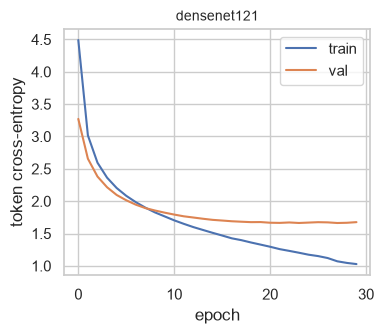

In [6]:
names = list(HISTS)
fig, axes = plt.subplots(1, len(names), figsize=(4 * len(names), 3.5), sharey=True)
axes = np.atleast_1d(axes)
for a, n in zip(axes, names):
    a.plot(HISTS[n]["train"], label="train"); a.plot(HISTS[n]["val"], label="val")
    a.set_title(n.replace("cnnlstm_", ""), fontsize=10); a.set_xlabel("epoch")
axes[0].set_ylabel("token cross-entropy"); axes[0].legend()
plt.tight_layout(); plt.show()

## 5 · Learning visual findings and generating reports
Fine-tune the last DenseNet121 block using weak study-level labels derived from MeSH. An unmentioned finding is treated as absent for training, so these labels can be incomplete. At generation time only the frontal image is available. An auxiliary head learns to predict the labels from the spatial features. Its probabilities form an extra token for the report decoder. Compare two training weights on validation data. Report both classes' F1 and the number of unique reports alongside word overlap.

In [7]:
import math, re
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

PAD, SOS, EOS, UNK = 0, 1, 2, 3
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def to_model_input(gray_uint8, device):
    """Grey uint8 images [B, H, W] -> normalised 3-channel float tensor [B, 3, H, W] (ImageNet statistics)."""
    x = torch.as_tensor(np.asarray(gray_uint8)).to(device).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
    mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
    std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)
    return (x - mean) / std


class SpatialBackbone(nn.Module):
    """A CNN that returns its final feature MAP (B, C, h, w) instead of one pooled vector.
    For a 224x224 input every backbone gives a 7x7 grid, i.e. 49 image 'tokens' for the Transformer."""
    DIMS = {"resnet50": 2048, "vgg16": 512, "densenet121": 1024, "efficientnet_b0": 1280}

    def __init__(self, name, pretrained=False):
        super().__init__()
        W = (lambda w: w.DEFAULT) if pretrained else (lambda w: None)
        if name == "resnet50":
            m = models.resnet50(weights=W(models.ResNet50_Weights))
            self.body = nn.Sequential(*list(m.children())[:-2])
        elif name == "vgg16":
            self.body = models.vgg16(weights=W(models.VGG16_Weights)).features
        elif name == "densenet121":
            self.body = nn.Sequential(models.densenet121(weights=W(models.DenseNet121_Weights)).features, nn.ReLU())
        elif name == "efficientnet_b0":
            self.body = models.efficientnet_b0(weights=W(models.EfficientNet_B0_Weights)).features
        else:
            raise ValueError(f"unknown backbone: {name}")
        self.name, self.out_dim = name, self.DIMS[name]

    def forward(self, x):
        return self.body(x)


class TransformerCaptioner(nn.Module):
    """Image-token encoder + autoregressive Transformer decoder (pre-LayerNorm).

    image grid [B, N, C] --LayerNorm, Dropout, Linear--> [B, N, d] --+ learned position--> TransformerEncoder (self-attention)
    words  [B, T]        --Embedding*sqrt(d) + position--> TransformerDecoder (masked self-attention + cross-attention to the image)
                         --> Linear tied to the embedding --> [B, T, vocab] next-word scores
    """

    def __init__(self, feat_dim, vocab_size, n_img_tokens, max_len, d_model=256, heads=8,
                 enc_layers=2, dec_layers=3, ff=512, dropout=0.2):
        super().__init__()
        self.d_model = d_model
        self.findings = nn.Linear(d_model, 9)
        self.finding_token = nn.Linear(9, d_model)

        self.feat_norm = nn.LayerNorm(feat_dim)
        self.feat_drop = nn.Dropout(dropout)
        self.feat_proj = nn.Linear(feat_dim, d_model)
        self.img_pos = nn.Parameter(torch.zeros(1, n_img_tokens, d_model))
        nn.init.normal_(self.img_pos, std=0.02)
        enc_layer = nn.TransformerEncoderLayer(d_model, heads, ff, dropout, activation="gelu",
                                               batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(enc_layer, enc_layers, norm=nn.LayerNorm(d_model),
                                             enable_nested_tensor=False)

        self.embed = nn.Embedding(vocab_size, d_model, padding_idx=PAD)
        nn.init.normal_(self.embed.weight, mean=0.0, std=d_model ** -0.5)
        with torch.no_grad():
            self.embed.weight[PAD].zero_()
        self.txt_pos = nn.Embedding(max_len, d_model)
        nn.init.normal_(self.txt_pos.weight, std=0.02)
        dec_layer = nn.TransformerDecoderLayer(d_model, heads, ff, dropout, activation="gelu",
                                               batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(dec_layer, dec_layers, norm=nn.LayerNorm(d_model))
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(d_model, vocab_size, bias=False)
        self.out.weight = self.embed.weight

    def encode(self, feats):
        x = self.feat_proj(self.feat_drop(self.feat_norm(feats.float())))
        spatial = self.encoder(x + self.img_pos)
        logits = self.findings(spatial.mean(1))
        token = self.finding_token(logits.sigmoid()).unsqueeze(1)
        return torch.cat((token, spatial), dim=1)

    def finding_logits(self, memory):
        return self.findings(memory[:, 1:].mean(1))

    def decode(self, memory, words):
        T = words.size(1)
        pos = torch.arange(T, device=words.device)
        y = self.drop(self.embed(words) * math.sqrt(self.d_model) + self.txt_pos(pos))
        causal = torch.triu(torch.ones(T, T, dtype=torch.bool, device=words.device), diagonal=1)
        return self.decoder(y, memory, tgt_mask=causal)

    def forward(self, feats, words_in):
        return self.out(self.decode(self.encode(feats), words_in))


def _repeats_ngram(seq, nxt, n):
    if n <= 0 or len(seq) < n - 1:
        return False
    cand = tuple(seq[-(n - 1):]) + (nxt,)
    return any(tuple(seq[i:i + n]) == cand for i in range(len(seq) - n + 1))


@torch.no_grad()
def tf_beam_search(model, feats1, beam=3, max_len=100, no_repeat=4):
    """Beam search for ONE image. feats1: [1, N, C]. Returns word ids (no <sos>; may end with <eos>).
    The same 4-word phrase is never repeated inside one report; scores are length-normalised."""
    model.eval()
    memory = model.encode(feats1)
    seqs, scores, done = [[SOS]], [0.0], [False]
    for _ in range(max_len):
        active = [i for i in range(len(seqs)) if not done[i]]
        if not active:
            break
        inp = torch.tensor([seqs[i] for i in active], device=feats1.device)
        hid = model.decode(memory.expand(len(active), -1, -1), inp)[:, -1]
        logp = F.log_softmax(model.out(hid).float(), dim=-1)
        logp[:, [PAD, SOS, UNK]] = -1e9
        cands = [(scores[i], seqs[i], True) for i in range(len(seqs)) if done[i]]
        for row, i in enumerate(active):
            top_lp, top_id = logp[row].topk(min(beam * 3, logp.size(1)))
            kept = 0
            for lp, w in zip(top_lp.tolist(), top_id.tolist()):
                if w != EOS and _repeats_ngram(seqs[i], w, no_repeat):
                    continue
                cands.append((scores[i] + lp, seqs[i] + [w], w == EOS))
                kept += 1
                if kept == beam:
                    break
            if kept == 0:
                cands.append((scores[i] - 1e3, seqs[i] + [EOS], True))
        cands.sort(key=lambda c: c[0] / len(c[1]), reverse=True)
        cands = cands[:beam]
        seqs, scores, done = [c[1] for c in cands], [c[0] for c in cands], [c[2] for c in cands]
    best = max(range(len(seqs)), key=lambda i: scores[i] / len(seqs[i]))
    return seqs[best][1:]


def ids_to_text(ids, itos):
    words = []
    for i in ids:
        if i == EOS:
            break
        if i in (PAD, SOS):
            continue
        words.append(itos[i])
    return re.sub(r"\s+([.,])", r"\1", " ".join(words))

In [8]:
TF_FEAT_DIM = SpatialBackbone.DIMS[TF_BACKBONE]
TF_TOKENS = (IMG_SIZE // 32) ** 2
MAX_POS = MAX_TOK + 2

def make_transformer():
    return TransformerCaptioner(TF_FEAT_DIM, V, TF_TOKENS, MAX_POS, TF_D_MODEL, TF_HEADS,
                                TF_ENC_LAYERS, TF_DEC_LAYERS, TF_FF, TF_DROPOUT)

demo = make_transformer().eval()

def n_params(*parts):
    return sum(p.numel() if isinstance(p, nn.Parameter) else sum(q.numel() for q in p.parameters()) for p in parts)

rows = [("finding prediction and conditioning", n_params(demo.findings, demo.finding_token)),("image projection (LayerNorm + Linear)", n_params(demo.feat_norm, demo.feat_proj)),
        ("image position embedding", n_params(demo.img_pos)),
        (f"Transformer encoder ({TF_ENC_LAYERS} layers)", n_params(demo.encoder)),
        ("word embedding (also the output layer)", n_params(demo.embed)),
        ("word position embedding", n_params(demo.txt_pos)),
        (f"Transformer decoder ({TF_DEC_LAYERS} layers)", n_params(demo.decoder))]
print(pd.DataFrame(rows, columns=["component", "parameters"]).to_string(index=False, formatters={"parameters": "{:,}".format}))
print("total trainable parameters:", f"{sum(p.numel() for p in demo.parameters()):,}", "(the frozen CNN is not counted)")


g = torch.randn(1, TF_TOKENS, TF_FEAT_DIM); w = torch.randint(4, V, (1, 20))
with torch.no_grad():
    x = demo.feat_proj(demo.feat_norm(g)); mem = demo.encode(g)
    hid = demo.decode(mem, w); scores = demo.out(hid)
print("\nShapes for one X-ray and a 20-word prefix:")
for label, t in [("CNN feature grid (49 tokens x channels)", g), ("after projection to the Transformer width", x),
                 ("encoder output = image memory", mem), ("word ids", w), ("decoder output", hid),
                 ("next-word scores (one per vocabulary word)", scores)]:
    print(f"  {label:46s}{tuple(t.shape)}")
print("\nOne encoder layer:"); print(demo.encoder.layers[0])
print("\nOne decoder layer:"); print(demo.decoder.layers[0])
del demo

                             component parameters
   finding prediction and conditioning      4,873
 image projection (LayerNorm + Linear)    264,448
              image position embedding     12,544
        Transformer encoder (2 layers)  1,054,720
word embedding (also the output layer)    257,792
               word position embedding     22,272
        Transformer decoder (3 layers)  2,372,864
total trainable parameters: 3,989,513 (the frozen CNN is not counted)

Shapes for one X-ray and a 20-word prefix:
  CNN feature grid (49 tokens x channels)       (1, 49, 1024)
  after projection to the Transformer width     (1, 49, 256)
  encoder output = image memory                 (1, 50, 256)
  word ids                                      (1, 20)
  decoder output                                (1, 20, 256)
  next-word scores (one per vocabulary word)    (1, 20, 1007)

One encoder layer:
TransformerEncoderLayer(
  (self_attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLi

In [9]:
patterns = {
    "cardiomegaly": "cardiomegaly",
    "effusion": "pleural effusion",
    "atelectasis": "atelectasis",
    "edema": "pulmonary edema",
    "pneumothorax": "pneumothorax",
    "nodule": "nodule|coin lesion",
    "opacity": "opacity|opacities",
    "hyperinflation": "hyperinflation|hyperdistention|hyperexpanded",
}
tags = data["MeSH"].fillna("").str.lower()
targets = np.column_stack([Y] + [tags.str.contains(pattern).to_numpy() for pattern in patterns.values()])
finding_targets = torch.tensor(targets, dtype=torch.float32, device=DEVICE)
train_counts = finding_targets[IDX["train"]].sum(0)
active = (train_counts > 0) & (train_counts < len(IDX["train"]))
weights = ((len(IDX["train"]) - train_counts) / train_counts.clamp_min(1)).sqrt().clamp(0.5, 8)
print(pd.Series(train_counts.cpu().numpy(), index=["abnormal", *patterns], name="training positives"))

def finding_loss(logits, ids):
    return F.binary_cross_entropy_with_logits(logits[:, active], finding_targets[ids][:, active],
                                               pos_weight=weights[active])

set_seed()
visual_net = SpatialBackbone(TF_BACKBONE, PRETRAINED).to(DEVICE)
visual_net.requires_grad_(False)
visual_net.body[0].denseblock4.requires_grad_(True)
visual_net.body[0].norm5.requires_grad_(True)
visual_head = nn.Linear(TF_FEAT_DIM, finding_targets.shape[1]).to(DEVICE)
optimizer = torch.optim.AdamW([
    {"params": [p for p in visual_net.parameters() if p.requires_grad], "lr": 3e-5},
    {"params": visual_head.parameters(), "lr": 4e-4}
])
best_visual_loss = float("inf")
for epoch in range(2 if QUICK_TEST else 8):
    for split in ("train", "val"):
        training = split == "train"
        visual_net.eval()
        visual_net.body[0].denseblock4.train(training)
        ids = np.random.permutation(IDX[split]) if training else IDX[split]
        total = 0.0
        for start in range(0, len(ids), 12):
            batch_ids = ids[start:start + 12]
            with torch.set_grad_enabled(training):
                grid = visual_net(to_model_input(IMGS[batch_ids], DEVICE))
                loss = finding_loss(visual_head(grid.mean((2, 3))), batch_ids)
                if training:
                    optimizer.zero_grad()
                    loss.backward()
                    optimizer.step()
            total += float(loss.detach()) * len(batch_ids)
        if not training:
            val_loss = total / len(ids)
            print(f"Visual epoch {epoch+1}: validation finding loss {val_loss:.4f}")
            if val_loss < best_visual_loss:
                best_visual_loss = val_loss
                best_visual_state = copy.deepcopy(visual_net.state_dict())
visual_net.load_state_dict(best_visual_state)
visual_net.eval()
with torch.no_grad():
    grids = []
    for start in tqdm(range(0, len(IMGS), 16), desc="IU-tuned image features"):
        grid = visual_net(to_model_input(IMGS[start:start+16], DEVICE))
        grids.append(grid.flatten(2).transpose(1, 2).half().cpu())
TF_X = torch.cat(grids).to(DEVICE)
del grids, best_visual_state
assert TF_X.shape == (len(data), TF_TOKENS, TF_FEAT_DIM)


abnormal          1582.0
cardiomegaly       226.0
effusion            91.0
atelectasis        205.0
edema               26.0
pneumothorax        18.0
nodule              71.0
opacity            284.0
hyperinflation     150.0
Name: training positives, dtype: float32
Visual epoch 1: validation finding loss 0.4855
Visual epoch 2: validation finding loss 0.4570
Visual epoch 3: validation finding loss 0.4502
Visual epoch 4: validation finding loss 0.4531
Visual epoch 5: validation finding loss 0.4932
Visual epoch 6: validation finding loss 0.5168
Visual epoch 7: validation finding loss 0.5679
Visual epoch 8: validation finding loss 0.6070


IU-tuned image features: 100%|██████████| 224/224 [05:41<00:00,  1.53s/it]


In [10]:
def lr_schedule(step, total, warm, peak):
    if step < warm:
        return peak * (step + 1) / warm
    prog = (step - warm) / max(1, total - warm)
    return peak * (0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * prog)))

def train_transformer(model, X, epochs, peak_lr, batch, aux_weight, smoothing=0.1, patience=8):
    model.to(DEVICE)
    parameters = model.parameters()
    opt = torch.optim.AdamW(parameters, lr=peak_lr, betas=(0.9, 0.98), weight_decay=0.01)
    total = epochs * math.ceil(len(IDX["train"]) / batch)
    warm = max(1, int(0.08 * total))
    best, best_state, bad, hist, step = 1e9, None, 0, {"train": [], "val": []}, 0
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(IDX["train"]); tot, n = 0.0, 0
        for i in range(0, len(perm), batch):
            b = as_idx(perm[i:i + batch])
            if len(b) < 2:
                continue
            c = CAPS[b]
            c = c[:, :max(int((c != PAD).sum(1).max()), 2)]
            for grp in opt.param_groups:
                grp["lr"] = lr_schedule(step, total, warm, peak_lr)
            memory = model.encode(X[b])
            logits = model.out(model.decode(memory, c[:, :-1]))
            tgt = c[:, 1:]
            flat_l, flat_t = logits.reshape(-1, V), tgt.reshape(-1)
            loss = F.cross_entropy(flat_l, flat_t, ignore_index=PAD, label_smoothing=smoothing)
            loss = loss + aux_weight * finding_loss(model.finding_logits(memory), b)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); step += 1
            with torch.no_grad():
                tot += F.cross_entropy(flat_l, flat_t, ignore_index=PAD, reduction="sum").item()
                n += (flat_t != PAD).sum().item()
        v = eval_loss(model, X, prep_feat, IDX["val"], batch)
        hist["train"].append(tot / n); hist["val"].append(v)
        print(f"  [transformer] epoch {ep + 1:02d}/{epochs} | train loss {tot / n:.3f} | val loss {v:.3f} | "
              f"val ppl {math.exp(v):.1f} | lr {opt.param_groups[0]['lr']:.1e}")
        if v < best - 1e-4:
            best, bad, best_state = v, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience:
                print("  early stopping"); break
    model.load_state_dict(best_state)
    return hist

@torch.no_grad()
def tf_generate(model, X, idx, beam=BEAM_SIZE):
    model.eval(); outs = []
    for i in tqdm(idx, desc="generating reports"):
        ids = tf_beam_search(model, X[as_idx([i])].float(), beam, MAX_TOK + 1, NO_REPEAT_NGRAM)
        outs.append(ids_to_text(ids, itos))
    return outs

In [11]:
selection_ids = IDX["val"]
if len(selection_ids) > 128:
    selection_ids, _ = train_test_split(selection_ids, train_size=128, stratify=Y[selection_ids], random_state=SEED)
selection_rows = []
best_rank = (-1, -1)
t0 = time.time()
for aux_weight in [0.2, 0.7]:
    set_seed()
    candidate = make_transformer().to(DEVICE)
    history = train_transformer(candidate, TF_X, EPOCHS_TF, LR_TF, BATCH_TF, aux_weight)
    validation_text = tf_generate(candidate, TF_X, selection_ids)
    metrics = evaluate_generation("validation", data.uid.values[selection_ids], validation_text, save=False)
    selection_rows.append({"aux_weight": aux_weight, "studies": len(selection_ids), **metrics})
    rank = (metrics["Macro-F1"] + metrics["ROUGE-L"] + metrics["BLEU-4"], metrics["Distinct"])
    if rank > best_rank:
        best_rank, selected_weight = rank, aux_weight
        best_weights = {k: v.detach().cpu().clone() for k, v in candidate.state_dict().items()}
        HISTS["cnn_transformer"] = history
    del candidate
selection = pd.DataFrame(selection_rows)
display(selection.round(4))
selection.to_csv(Path(RESULTS_DIR) / "transformer_validation.csv", index=False)
tf_model = make_transformer().to(DEVICE)
tf_model.load_state_dict(best_weights)
hyps = tf_generate(tf_model, TF_X, IDX["test"])
tf_metrics = evaluate_generation("cnn_transformer", TEST_UIDS, hyps)
GEN_META["cnn_transformer"] = {"aux_weight": selected_weight, "train_time_s": round(time.time()-t0),
                               "trainable_params": sum(p.numel() for p in tf_model.parameters())}
save_json(META_PATH, GEN_META)
show_metrics("cnn_transformer", tf_metrics)

  [transformer] epoch 01/30 | train loss 6.396 | val loss 4.470 | val ppl 87.4 | lr 2.1e-04
  [transformer] epoch 02/30 | train loss 3.681 | val loss 2.938 | val ppl 18.9 | lr 4.2e-04
  [transformer] epoch 03/30 | train loss 2.832 | val loss 2.482 | val ppl 12.0 | lr 5.0e-04
  [transformer] epoch 04/30 | train loss 2.510 | val loss 2.283 | val ppl 9.8 | lr 5.0e-04
  [transformer] epoch 05/30 | train loss 2.329 | val loss 2.151 | val ppl 8.6 | lr 4.9e-04
  [transformer] epoch 06/30 | train loss 2.204 | val loss 2.073 | val ppl 7.9 | lr 4.8e-04
  [transformer] epoch 07/30 | train loss 2.107 | val loss 2.015 | val ppl 7.5 | lr 4.7e-04
  [transformer] epoch 08/30 | train loss 2.022 | val loss 1.965 | val ppl 7.1 | lr 4.5e-04
  [transformer] epoch 09/30 | train loss 1.951 | val loss 1.934 | val ppl 6.9 | lr 4.4e-04
  [transformer] epoch 10/30 | train loss 1.886 | val loss 1.890 | val ppl 6.6 | lr 4.2e-04
  [transformer] epoch 11/30 | train loss 1.829 | val loss 1.888 | val ppl 6.6 | lr 4.0e

generating reports: 100%|██████████| 128/128 [00:41<00:00,  3.08it/s]


  [transformer] epoch 01/30 | train loss 6.401 | val loss 4.438 | val ppl 84.6 | lr 2.1e-04
  [transformer] epoch 02/30 | train loss 3.671 | val loss 2.944 | val ppl 19.0 | lr 4.2e-04
  [transformer] epoch 03/30 | train loss 2.831 | val loss 2.488 | val ppl 12.0 | lr 5.0e-04
  [transformer] epoch 04/30 | train loss 2.508 | val loss 2.282 | val ppl 9.8 | lr 5.0e-04
  [transformer] epoch 05/30 | train loss 2.328 | val loss 2.149 | val ppl 8.6 | lr 4.9e-04
  [transformer] epoch 06/30 | train loss 2.204 | val loss 2.080 | val ppl 8.0 | lr 4.8e-04
  [transformer] epoch 07/30 | train loss 2.111 | val loss 2.014 | val ppl 7.5 | lr 4.7e-04
  [transformer] epoch 08/30 | train loss 2.031 | val loss 1.961 | val ppl 7.1 | lr 4.5e-04
  [transformer] epoch 09/30 | train loss 1.962 | val loss 1.930 | val ppl 6.9 | lr 4.4e-04
  [transformer] epoch 10/30 | train loss 1.903 | val loss 1.889 | val ppl 6.6 | lr 4.2e-04
  [transformer] epoch 11/30 | train loss 1.850 | val loss 1.878 | val ppl 6.5 | lr 4.0e

generating reports: 100%|██████████| 128/128 [00:57<00:00,  2.24it/s]


,aux_weight,studies,BLEU-1,BLEU-2,BLEU-3,BLEU-4,ROUGE-L,Label-Acc,Label-F1,Macro-F1,UniqueReports,AvgLen,Distinct
0,0.2,128,0.3279,0.2188,0.1596,0.1217,0.3461,0.4844,0.3265,0.4544,22,30.2344,0.1719
1,0.7,128,0.2801,0.1839,0.1328,0.1003,0.3468,0.4453,0.2366,0.4005,15,26.5703,0.1172


generating reports: 100%|██████████| 537/537 [03:35<00:00,  2.49it/s]


cnn_transformer -> {'BLEU-1': 0.2926, 'BLEU-2': 0.1834, 'BLEU-3': 0.1232, 'BLEU-4': 0.0857, 'ROUGE-L': 0.3243, 'Label-Acc': 0.4804, 'Label-F1': 0.3212, 'Macro-F1': 0.4502, 'UniqueReports': 52, 'AvgLen': 29.1024, 'Distinct': 0.0968}


Saved iu_runs\full\a1d1656d70/report_generator.pt (45 MB). It contains plain tensors and numbers only, so it loads with weights_only=True.


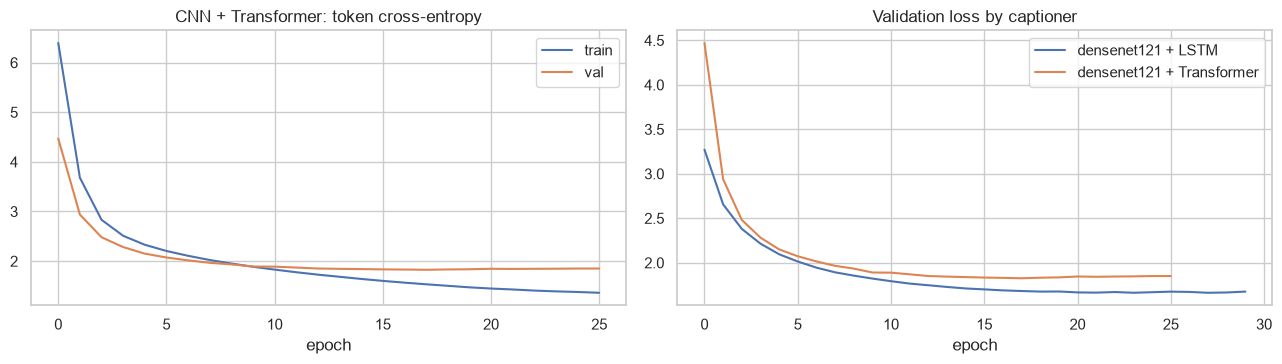

In [12]:
BUNDLE_PATH = f"{RESULTS_DIR}/report_generator{'_quick' if QUICK_TEST else ''}.pt"

def export_bundle(path, model, metrics):
    torch.manual_seed(SEED)
    backbone = copy.deepcopy(visual_net).to(DEVICE).eval()

    with torch.no_grad():
        again = backbone(to_model_input(IMGS[:4], DEVICE)).flatten(2).transpose(1, 2).half().float().cpu()
    if not torch.allclose(again, TF_X[:4].float().cpu(), rtol=2e-2, atol=2e-2):
        raise RuntimeError("Export verification failed. Re-run the visual training, feature extraction and Transformer stages in order.")
    backbone = backbone.cpu()
    cpu = lambda sd: {k: v.detach().cpu().clone() for k, v in sd.items()}
    bundle = {
        "format_version": 2,
        "config": dict(backbone=TF_BACKBONE, img_size=IMG_SIZE, feat_dim=TF_FEAT_DIM, n_img_tokens=TF_TOKENS, max_len=MAX_POS,
                       d_model=TF_D_MODEL, heads=TF_HEADS, enc_layers=TF_ENC_LAYERS, dec_layers=TF_DEC_LAYERS, ff=TF_FF,
                       dropout=TF_DROPOUT, max_tok=MAX_TOK, beam=BEAM_SIZE, no_repeat=NO_REPEAT_NGRAM),
        "itos": list(itos),
        "model_state": cpu(model.state_dict()),
        "backbone_state": cpu(backbone.state_dict()),
        "metrics": {k: float(v) for k, v in metrics.items()},
        "info": dict(dataset="IU X-Ray (Open-I chest X-rays)", trained_on=int(len(IDX["train"])), quick_test=bool(QUICK_TEST),
                     pretrained_backbone=bool(PRETRAINED), created=time.strftime("%Y-%m-%d %H:%M")),
    }
    torch.save(bundle, path)
    return os.path.getsize(path) / 1e6

size_mb = export_bundle(BUNDLE_PATH, tf_model, tf_metrics)
torch.load(BUNDLE_PATH, map_location="cpu", weights_only=True)
print(f"Saved {BUNDLE_PATH} ({size_mb:.0f} MB). It contains plain tensors and numbers only, so it loads with weights_only=True.")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
h = HISTS["cnn_transformer"]
ax[0].plot(h["train"], label="train"); ax[0].plot(h["val"], label="val")
ax[0].set_title("CNN + Transformer: token cross-entropy"); ax[0].set_xlabel("epoch"); ax[0].legend()
same_bb = f"cnnlstm_{TF_BACKBONE}"
if same_bb in HISTS:
    ax[1].plot(HISTS[same_bb]["val"], label=f"{TF_BACKBONE} + LSTM")
    ax[1].plot(h["val"], label=f"{TF_BACKBONE} + Transformer")
    ax[1].set_title("Validation loss by captioner"); ax[1].set_xlabel("epoch"); ax[1].legend()
else:
    ax[1].axis("off")
plt.tight_layout(); plt.show()

## 6 · Held-out results and report review
Compare the two CNN depths and the fixed versus tuned ANN on the same test studies. For generation, inspect reference and prediction together, especially abnormal references paired with generic normal reports. The split controls overlap by study UID. This dataset export does not establish patient-level independence.

In [13]:
PRETTY = {"svm": "SVM (HOG+LBP)", "rf": "Random Forest (HOG+LBP)", "ann_tuned": "ANN tuned (deep features)",
          "baseline_constant": "Constant report", "baseline_knn": "kNN retrieval", "cnnlstm_custom": "Custom CNN + LSTM",
          "cnn_transformer": f"CNN + Transformer ({TF_BACKBONE})", "blip2": "BLIP-2 (LoRA)"}
for b in BACKBONES:
    PRETTY[f"ann_base_{b}"] = f"ANN untuned ({b})"
    PRETTY[f"cnnlstm_{b}"] = f"{b} + LSTM"


CLS = load_json(CLS_PATH, {})
PRETTY.update({"cnn_3": "CNN (3 blocks)", "cnn_5": "CNN (5 blocks)"})
order_cls = ["svm", "rf", "cnn_3", "cnn_5"] + [f"ann_base_{b}" for b in BACKBONES] + ["ann_tuned"]
rows = [{"model": PRETTY[k], "group": CLS[k]["group"], **{m: CLS[k]["test"][m] for m in ["accuracy", "precision", "recall", "f1", "auc"]}}
        for k in order_cls if k in CLS]
majority = int(Y[IDX["train"]].mean() >= 0.5)
majority_pred = np.full(len(TEST_UIDS), majority)
rows.insert(0, {"model": "Training majority", "group": "Baseline",
                **cls_eval(Y[IDX["test"]], majority_pred, majority_pred)})
cls_table = pd.DataFrame(rows)
print("CLASSIFICATION: normal vs abnormal (test set)")
display(cls_table.round(3))


order_gen = ["baseline_constant", "baseline_knn", "cnnlstm_custom"] + [f"cnnlstm_{b}" for b in BACKBONES] + ["cnn_transformer"]
gen_rows, GEN_DF = [], {}
for k in order_gen:
    path = f"{RESULTS_DIR}/preds_{k}.csv"
    if not os.path.exists(path):
        continue
    p = pd.read_csv(path).fillna("").set_index("uid")
    uids = [u for u in TEST_UIDS if u in p.index]
    if len(uids) < len(TEST_UIDS):
        print(f"note: {PRETTY[k]} has predictions for {len(uids)} of {len(TEST_UIDS)} test studies")
    GEN_DF[k] = p
    m = evaluate_generation(k, uids, p.loc[uids, "generated"].tolist(), save=False)
    gen_rows.append({"model": PRETTY[k], "key": k, **m, **{x: GEN_META.get(k, {}).get(x) for x in ["train_time_s", "trainable_params"]}})
gen_table = pd.DataFrame(gen_rows)
print("\nREPORT GENERATION (test set)")
display(gen_table.drop(columns="key").round(3))
cls_table.to_csv(Path(RESULTS_DIR) / "classification.csv", index=False)
gen_table.to_csv(Path(RESULTS_DIR) / "generation.csv", index=False)

CLASSIFICATION: normal vs abnormal (test set)


,model,group,accuracy,precision,recall,f1,auc
0,Training majority,Baseline,0.631,0.631,1.000,0.774,0.500
1,SVM (HOG+LBP),Classical ML (HOG+LBP),0.683,0.716,0.826,0.767,0.715
2,Random Forest (HOG+LBP),Classical ML (HOG+LBP),0.667,0.673,0.917,0.777,0.721
3,CNN (3 blocks),CNN from pixels,0.706,0.705,0.917,0.797,0.783
4,CNN (5 blocks),CNN from pixels,0.736,0.781,0.808,0.794,0.781
5,ANN untuned (resnet50),"ANN (untuned, deep features)",0.685,0.787,0.687,0.734,0.764
6,ANN untuned (densenet121),"ANN (untuned, deep features)",0.700,0.807,0.690,0.744,0.763
7,ANN tuned (deep features),"ANN (tuned, deep features)",0.687,0.775,0.711,0.742,0.763



REPORT GENERATION (test set)


,model,BLEU-1,BLEU-2,BLEU-3,BLEU-4,ROUGE-L,Label-Acc,Label-F1,Macro-F1,UniqueReports,AvgLen,Distinct,train_time_s,trainable_params
0,Constant report,0.182,0.115,0.079,0.057,0.328,0.369,0.000,0.269,1,21.000,0.002,NaN,NaN
1,kNN retrieval,0.361,0.218,0.141,0.097,0.294,0.587,0.644,0.575,361,42.311,0.672,NaN,NaN
2,Custom CNN + LSTM,0.208,0.133,0.091,0.066,0.332,0.369,0.000,0.269,3,22.622,0.006,4311.0,7591311.0
3,resnet50 + LSTM,0.315,0.199,0.134,0.095,0.322,0.387,0.068,0.306,70,31.816,0.130,900.0,4453615.0
4,densenet121 + LSTM,0.347,0.219,0.148,0.104,0.331,0.391,0.079,0.312,70,34.374,0.130,908.0,3402991.0
5,CNN + Transformer (densenet121),0.293,0.183,0.123,0.086,0.324,0.480,0.321,0.450,52,29.102,0.097,7180.0,3989513.0


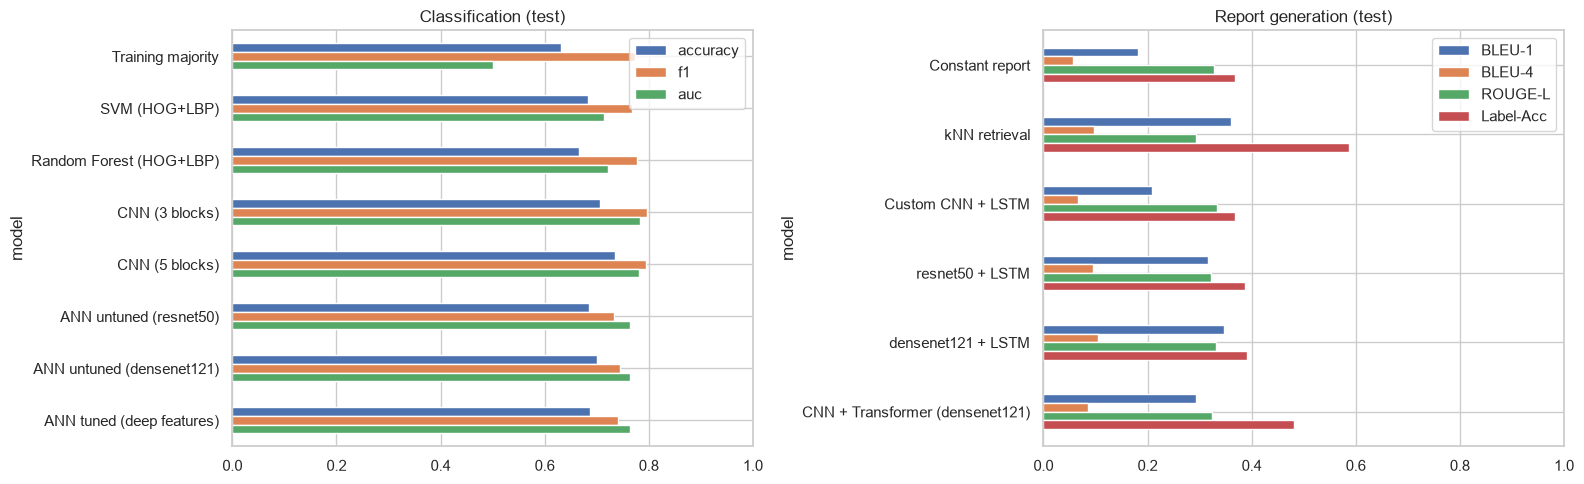

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ct = cls_table.set_index("model")[["accuracy", "f1", "auc"]]
ct.plot(kind="barh", ax=ax[0]); ax[0].set_title("Classification (test)"); ax[0].set_xlim(0, 1); ax[0].invert_yaxis()
gt = gen_table.set_index("model")[["BLEU-1", "BLEU-4", "ROUGE-L", "Label-Acc"]]
gt.plot(kind="barh", ax=ax[1]); ax[1].set_title("Report generation (test)"); ax[1].set_xlim(0, 1); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

In [15]:
rs = np.random.RandomState(1)
pool = [u for u in TEST_UIDS if all(u in GEN_DF[k].index for k in GEN_DF)]
picks = list(rs.choice([u for u in pool if _LAB[u] == 0], min(1, len([u for u in pool if _LAB[u] == 0])), replace=False)) + \
        list(rs.choice([u for u in pool if _LAB[u] == 1], min(2, len([u for u in pool if _LAB[u] == 1])), replace=False))
for u in picks:
    print("=" * 110)
    print(f"uid {u} | true label: {'abnormal' if _LAB[u] else 'normal'}")
    print("  GROUND TRUTH        :", _REF[u][:300])
    for k in GEN_DF:
        print(f"  {PRETTY[k]:22s}:", str(GEN_DF[k].loc[u, "generated"])[:300])

uid 3605 | true label: normal
  GROUND TRUTH        : heart size within normal limits. no focal airspace disease. no pleural effusion. no acute cardiopulmonary findings. specifically, no evidence of pleural effusion or hilar or mediastinal adenopathy.
  Constant report       : the heart is normal in size. the mediastinum is unremarkable. the lungs are clear. no acute disease.
  kNN retrieval         : pa and lateral views. stable postoperative changes with midline sternotomy and myocardial revascularization. cardiac size remains mildly enlarged but stable. there is mild vascular congestion. small bilateral pleural effusions are present, which are . mild pulmonary vascular congestion, with bilater
  Custom CNN + LSTM     : the heart is normal in size. the mediastinum is unremarkable. the lungs are clear. no acute disease.
  resnet50 + LSTM       : the heart size is normal. the mediastinal contour is within normal limits. the lungs are free of any focal infiltrates. there are no nodules 

In [16]:
review = GEN_DF["cnn_transformer"][["reference", "generated"]].copy()
review["mesh_abnormal"] = _LAB.loc[review.index]
review["predicted_abnormal_from_text"] = label_from_text(review.generated)
review.to_csv(Path(RESULTS_DIR) / "transformer_review.csv")
display(pd.crosstab(review.mesh_abnormal, review.predicted_abnormal_from_text, margins=True))
display(review.query("mesh_abnormal == 1 and predicted_abnormal_from_text == 0").head(5))
ordered = GEN_DF["cnn_transformer"].loc[TEST_UIDS, "generated"].tolist()
rng = np.random.default_rng(SEED)
checks = []
for repeat in range(21):
    if repeat == 0:
        test_text = ordered
    else:
        cycle = rng.permutation(len(ordered))
        perm = np.empty_like(cycle)
        perm[cycle] = np.roll(cycle, 1)
        test_text = [ordered[i] for i in perm]
    scores = evaluate_generation("pairing", TEST_UIDS, test_text, save=False)
    checks.append({"pairing": "correct" if repeat == 0 else "shuffled", **scores})
pairing = pd.DataFrame(checks)
display(pairing.groupby("pairing")[["Macro-F1","Label-Acc","Label-F1","ROUGE-L","BLEU-4","Distinct"]].mean())
pairing.to_csv(Path(RESULTS_DIR) / "image_pairing.csv", index=False)
print("Each shuffle pairs the same deterministic reports with different studies. Distinct stays fixed. Look for better agreement on the correct pairs.")


predicted_abnormal_from_text,0,1,All
mesh_abnormal,,,
0,192,6,198
1,273,66,339
All,465,72,537


,reference,generated,mesh_abnormal,predicted_abnormal_from_text
uid,,,,
13,the cardiac silhouette is borderline enlarged....,the heart is normal in size. the mediastinum i...,1,0
15,cardiomediastinal silhouette and pulmonary vas...,the heart is normal in size. the mediastinum i...,1,0
21,heart size normal. mediastinal silhouettes and...,"the lungs are clear bilaterally. specifically,...",1,0
45,stable cardiomegaly with vascular prominence w...,the heart is normal in size. the mediastinum i...,1,0
49,"the heart, pulmonary and mediastinum are withi...",the heart is normal in size. the mediastinum i...,1,0


,Macro-F1,Label-Acc,Label-F1,ROUGE-L,BLEU-4,Distinct
pairing,,,,,,
correct,0.450177,0.480447,0.321168,0.324266,0.085737,0.096834
shuffled,0.369378,0.404097,0.221411,0.324604,0.082672,0.096834


Each shuffle pairs the same deterministic reports with different studies. Distinct stays fixed. Look for better agreement on the correct pairs.


## 7 · Streamlit export
These next two cells are self-contained. The first writes the inference module, Streamlit app and requirements. The second copies the selected checkpoint into the app and creates a portable ZIP. For a checkpoint created by this notebook version, edit `CHECKPOINT` in the second cell. Use your own trained model file.

In [17]:
from pathlib import Path
import tempfile
import shutil

WEBAPP_DIR = Path(tempfile.mkdtemp(prefix="iu_streamlit_", dir=Path.cwd()))
(WEBAPP_DIR / "model").mkdir()
(WEBAPP_DIR / 'app.py').write_text(r'''from pathlib import Path
import hashlib

from PIL import Image, UnidentifiedImageError
import streamlit as st

from report_model import ReportGenerator

st.set_page_config(page_title="IU X-ray report generator")
st.title("Chest X-ray report generator")
st.caption("Deep learning project · Indiana University chest X-rays")
st.write("Upload one de-identified frontal chest X-ray to generate a research draft. The model can omit findings or invent them. For coursework use only.")
checkpoint = Path(__file__).parent / "model" / "report_generator.pt"
if not checkpoint.is_file():
    st.info("Run the notebook export or place your trained bundle in model/report_generator.pt.")
    st.stop()

@st.cache_resource
def load_model(path, modified):
    return ReportGenerator(path, device="cpu")

generator = load_model(str(checkpoint), checkpoint.stat().st_mtime_ns)
if generator.info.get("quick_test"):
    st.warning("This checkpoint was trained in quick-test mode. Use a full run for your presentation.")
upload = st.file_uploader("Frontal chest X-ray", type=["png", "jpg", "jpeg"])
if upload is not None:
    try:
        with Image.open(upload) as source:
            if source.format not in {"PNG", "JPEG"} or source.width * source.height > 20_000_000:
                st.error("Choose a PNG or JPEG image under 20 megapixels.")
                st.stop()
            scan = source.copy()
    except (UnidentifiedImageError, OSError, Image.DecompressionBombError):
        st.error("The image could not be opened. Choose a readable PNG or JPEG file.")
        st.stop()
    image_key = hashlib.sha256(upload.getbuffer()).hexdigest()
    st.image(scan, width=320)
    if st.button("Generate report", type="primary"):
        with st.spinner("Generating draft…"):
            result = generator.generate(scan)
        st.session_state["draft"] = (image_key, result["report"])
    draft = st.session_state.get("draft")
    if draft and draft[0] == image_key:
        st.subheader("Generated draft")
        st.write(draft[1])
        st.download_button("Download report", draft[1], "generated_report.txt", "text/plain")''', encoding='utf-8')
(WEBAPP_DIR / 'report_model.py').write_text(r'''
import math, re
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

PAD, SOS, EOS, UNK = 0, 1, 2, 3
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def to_model_input(gray_uint8, device):
    """Grey uint8 images [B, H, W] -> normalised 3-channel float tensor [B, 3, H, W] (ImageNet statistics)."""
    x = torch.as_tensor(np.asarray(gray_uint8)).to(device).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
    mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
    std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)
    return (x - mean) / std


class SpatialBackbone(nn.Module):
    """A CNN that returns its final feature MAP (B, C, h, w) instead of one pooled vector.
    For a 224x224 input every backbone gives a 7x7 grid, i.e. 49 image 'tokens' for the Transformer."""
    DIMS = {"resnet50": 2048, "vgg16": 512, "densenet121": 1024, "efficientnet_b0": 1280}

    def __init__(self, name, pretrained=False):
        super().__init__()
        W = (lambda w: w.DEFAULT) if pretrained else (lambda w: None)
        if name == "resnet50":
            m = models.resnet50(weights=W(models.ResNet50_Weights))
            self.body = nn.Sequential(*list(m.children())[:-2])
        elif name == "vgg16":
            self.body = models.vgg16(weights=W(models.VGG16_Weights)).features
        elif name == "densenet121":
            self.body = nn.Sequential(models.densenet121(weights=W(models.DenseNet121_Weights)).features, nn.ReLU())
        elif name == "efficientnet_b0":
            self.body = models.efficientnet_b0(weights=W(models.EfficientNet_B0_Weights)).features
        else:
            raise ValueError(f"unknown backbone: {name}")
        self.name, self.out_dim = name, self.DIMS[name]

    def forward(self, x):
        return self.body(x)


class TransformerCaptioner(nn.Module):
    """Image-token encoder + autoregressive Transformer decoder (pre-LayerNorm).

    image grid [B, N, C] --LayerNorm, Dropout, Linear--> [B, N, d] --+ learned position--> TransformerEncoder (self-attention)
    words  [B, T]        --Embedding*sqrt(d) + position--> TransformerDecoder (masked self-attention + cross-attention to the image)
                         --> Linear tied to the embedding --> [B, T, vocab] next-word scores
    """

    def __init__(self, feat_dim, vocab_size, n_img_tokens, max_len, d_model=256, heads=8,
                 enc_layers=2, dec_layers=3, ff=512, dropout=0.2):
        super().__init__()
        self.d_model = d_model
        self.findings = nn.Linear(d_model, 9)
        self.finding_token = nn.Linear(9, d_model)

        self.feat_norm = nn.LayerNorm(feat_dim)
        self.feat_drop = nn.Dropout(dropout)
        self.feat_proj = nn.Linear(feat_dim, d_model)
        self.img_pos = nn.Parameter(torch.zeros(1, n_img_tokens, d_model))
        nn.init.normal_(self.img_pos, std=0.02)
        enc_layer = nn.TransformerEncoderLayer(d_model, heads, ff, dropout, activation="gelu",
                                               batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(enc_layer, enc_layers, norm=nn.LayerNorm(d_model),
                                             enable_nested_tensor=False)

        self.embed = nn.Embedding(vocab_size, d_model, padding_idx=PAD)
        nn.init.normal_(self.embed.weight, mean=0.0, std=d_model ** -0.5)
        with torch.no_grad():
            self.embed.weight[PAD].zero_()
        self.txt_pos = nn.Embedding(max_len, d_model)
        nn.init.normal_(self.txt_pos.weight, std=0.02)
        dec_layer = nn.TransformerDecoderLayer(d_model, heads, ff, dropout, activation="gelu",
                                               batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(dec_layer, dec_layers, norm=nn.LayerNorm(d_model))
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(d_model, vocab_size, bias=False)
        self.out.weight = self.embed.weight

    def encode(self, feats):
        x = self.feat_proj(self.feat_drop(self.feat_norm(feats.float())))
        spatial = self.encoder(x + self.img_pos)
        logits = self.findings(spatial.mean(1))
        token = self.finding_token(logits.sigmoid()).unsqueeze(1)
        return torch.cat((token, spatial), dim=1)

    def finding_logits(self, memory):
        return self.findings(memory[:, 1:].mean(1))

    def decode(self, memory, words):
        T = words.size(1)
        pos = torch.arange(T, device=words.device)
        y = self.drop(self.embed(words) * math.sqrt(self.d_model) + self.txt_pos(pos))
        causal = torch.triu(torch.ones(T, T, dtype=torch.bool, device=words.device), diagonal=1)
        return self.decoder(y, memory, tgt_mask=causal)

    def forward(self, feats, words_in):
        return self.out(self.decode(self.encode(feats), words_in))


def _repeats_ngram(seq, nxt, n):
    if n <= 0 or len(seq) < n - 1:
        return False
    cand = tuple(seq[-(n - 1):]) + (nxt,)
    return any(tuple(seq[i:i + n]) == cand for i in range(len(seq) - n + 1))


@torch.no_grad()
def tf_beam_search(model, feats1, beam=3, max_len=100, no_repeat=4):
    """Beam search for ONE image. feats1: [1, N, C]. Returns word ids (no <sos>; may end with <eos>).
    The same 4-word phrase is never repeated inside one report; scores are length-normalised."""
    model.eval()
    memory = model.encode(feats1)
    seqs, scores, done = [[SOS]], [0.0], [False]
    for _ in range(max_len):
        active = [i for i in range(len(seqs)) if not done[i]]
        if not active:
            break
        inp = torch.tensor([seqs[i] for i in active], device=feats1.device)
        hid = model.decode(memory.expand(len(active), -1, -1), inp)[:, -1]
        logp = F.log_softmax(model.out(hid).float(), dim=-1)
        logp[:, [PAD, SOS, UNK]] = -1e9
        cands = [(scores[i], seqs[i], True) for i in range(len(seqs)) if done[i]]
        for row, i in enumerate(active):
            top_lp, top_id = logp[row].topk(min(beam * 3, logp.size(1)))
            kept = 0
            for lp, w in zip(top_lp.tolist(), top_id.tolist()):
                if w != EOS and _repeats_ngram(seqs[i], w, no_repeat):
                    continue
                cands.append((scores[i] + lp, seqs[i] + [w], w == EOS))
                kept += 1
                if kept == beam:
                    break
            if kept == 0:
                cands.append((scores[i] - 1e3, seqs[i] + [EOS], True))
        cands.sort(key=lambda c: c[0] / len(c[1]), reverse=True)
        cands = cands[:beam]
        seqs, scores, done = [c[1] for c in cands], [c[0] for c in cands], [c[2] for c in cands]
    best = max(range(len(seqs)), key=lambda i: scores[i] / len(seqs[i]))
    return seqs[best][1:]


def ids_to_text(ids, itos):
    words = []
    for i in ids:
        if i == EOS:
            break
        if i in (PAD, SOS):
            continue
        words.append(itos[i])
    return re.sub(r"\s+([.,])", r"\1", " ".join(words))

import time
from PIL import Image, ImageOps

RESAMPLE = getattr(Image, "Resampling", Image).BICUBIC


def pil_to_gray_uint8(img, size):
    """PIL image -> grey uint8 array [size, size], using the same resize as the training pipeline."""
    img = ImageOps.exif_transpose(img)
    if img.mode in ("I", "I;16", "I;16L", "I;16B"):
        arr = np.asarray(img, dtype=np.float32)
        lo, hi = float(arr.min()), float(arr.max())
        img = Image.fromarray(((arr - lo) / max(hi - lo, 1.0) * 255.0).astype(np.uint8))
    else:
        img = img.convert("L")
    return np.asarray(img.resize((size, size), RESAMPLE, reducing_gap=2.0), dtype=np.uint8)


def image_warnings(img):
    """Cheap heuristics that flag uploads which probably are not chest X-rays. They can be wrong."""
    notes = []
    w, h = img.size
    if min(w, h) < 256:
        notes.append(f"The image is small ({w} x {h} px). Chest X-rays are usually much larger, so detail may be lost.")
    if max(w, h) / max(min(w, h), 1) > 1.6:
        notes.append("The image has an unusual shape for a chest X-ray. Check that it is not cropped.")
    if img.mode in ("RGB", "RGBA", "P"):
        rgb = np.asarray(img.convert("RGB").resize((128, 128)), dtype=np.float32)
        spread = (np.abs(rgb[..., 0] - rgb[..., 1]).mean() + np.abs(rgb[..., 1] - rgb[..., 2]).mean()) / 2
        if spread > 8:
            notes.append("This image is in colour, which a chest X-ray normally is not. It may not be an X-ray.")
    return notes


def prettify(text):
    """The model writes lower-case text. Capitalise sentence starts for display only."""
    return re.sub(r"(^|[.!?]\s+)([a-z])", lambda m: m.group(1) + m.group(2).upper(), text.strip())


class ReportGenerator:
    """Loads the bundle written by the notebook and turns a PIL image into a report."""

    def __init__(self, bundle_path, device=None):
        b = torch.load(bundle_path, map_location="cpu", weights_only=True)
        if b.get("format_version") != 2:
            raise ValueError("Unsupported model file version. Re-export it from the notebook.")
        self.cfg, self.itos = b["config"], b["itos"]
        c = self.cfg
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        self.backbone = SpatialBackbone(c["backbone"], pretrained=False)
        self.backbone.load_state_dict(b["backbone_state"])
        self.backbone.to(self.device).eval()
        self.model = TransformerCaptioner(c["feat_dim"], len(self.itos), c["n_img_tokens"], c["max_len"],
                                          c["d_model"], c["heads"], c["enc_layers"], c["dec_layers"], c["ff"], c["dropout"])
        self.model.load_state_dict(b["model_state"])
        self.model.to(self.device).eval()
        n_params = sum(p.numel() for p in self.model.parameters())

        metrics = {k: float(v) for k, v in b.get("metrics", {}).items()
                   if isinstance(v, (int, float)) and math.isfinite(v)}
        self.info = {**b.get("info", {}), "backbone": c["backbone"], "vocab_size": len(self.itos),
                     "decoder_params": n_params, "metrics": metrics, "device": self.device.type}

    @torch.no_grad()
    def generate_raw(self, img, beam=None):
        c = self.cfg
        x = to_model_input(pil_to_gray_uint8(img, c["img_size"])[None], self.device)
        grid = self.backbone(x).flatten(2).transpose(1, 2)
        grid = grid.half().float()
        ids = tf_beam_search(self.model, grid, beam or c["beam"], c["max_tok"] + 1, c["no_repeat"])
        return ids_to_text(ids, self.itos)

    def generate(self, img, beam=None):
        t0 = time.time()
        raw = self.generate_raw(img, beam)
        return {"report": prettify(raw), "raw": raw, "seconds": round(time.time() - t0, 2)}''', encoding='utf-8')
(WEBAPP_DIR / 'README.md').write_text(r'''# IU chest X-ray report generator

Streamlit demo for one de-identified frontal PNG or JPEG chest X-ray. The model was trained to generate combined findings and impression text. Generated text is an educational draft and can contain errors.

## Run locally
Use Python 3.11. In this folder run:

```bash
python -m pip install -r requirements.txt
python -m streamlit run app.py
```

## GitHub and Streamlit
Use this folder as the repository root. Include app.py, report_model.py, requirements.txt and model/report_generator.pt. Keep the X-ray dataset, caches and prediction CSVs on your computer. For Streamlit Community Cloud select your repository and app.py as the entry point. The app loads its bundled checkpoint on CPU.
''', encoding='utf-8')
(WEBAPP_DIR / 'requirements.txt').write_text(r'''torch>=2.2,<3
torchvision>=0.17,<1
streamlit>=1.32,<2
Pillow>=10
numpy>=1.26
''', encoding='utf-8')
print("App folder:", WEBAPP_DIR)

App folder: d:\iu_streamlit_0nbi4wcs


In [18]:
CHECKPOINT = Path(globals().get("BUNDLE_PATH", "results/report_generator.pt"))
if not CHECKPOINT.is_file():
    raise FileNotFoundError(f"Set CHECKPOINT to your report_generator.pt file. Tried {CHECKPOINT.resolve()}")
shutil.copy2(CHECKPOINT, WEBAPP_DIR / "model" / "report_generator.pt")
archive = shutil.make_archive(str(WEBAPP_DIR), "zip", WEBAPP_DIR)
print("GitHub-ready ZIP:", archive)
print(f'Launch from a terminal: python -m streamlit run "{WEBAPP_DIR / "app.py"}"')

GitHub-ready ZIP: d:\iu_streamlit_0nbi4wcs.zip
Launch from a terminal: python -m streamlit run "d:\iu_streamlit_0nbi4wcs\app.py"


### Verify export parity
After a training run, decode the same held-out images using the saved app bundle and the notebook. Stop here if they disagree. The previous-checkpoint shortcut can skip this cell.

In [19]:
import importlib.util
if "tf_model" in globals() and CHECKPOINT.resolve() == Path(BUNDLE_PATH).resolve():
    spec = importlib.util.spec_from_file_location("exported_report_model", WEBAPP_DIR / "report_model.py")
    exported = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(exported)
    deployed = exported.ReportGenerator(CHECKPOINT, device=DEVICE.type)
    for i in IDX["test"][:5]:
        with Image.open(data.path.iloc[i]) as image:
            app_text = deployed.generate_raw(image)
        assert app_text == tf_generate(tf_model, TF_X, [i])[0], f"Export mismatch on UID {data.uid.iloc[i]}"
    print("Export parity passed on five held-out studies.")
else:
    print("Existing-checkpoint export complete. Parity requires the corresponding training run.")

d:\iu_streamlit_0nbi4wcs\report_model.py:16: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  x = torch.as_tensor(np.asarray(gray_uint8)).to(device).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
generating reports: 100%|██████████| 1/1 [00:00<00:00,  2.60it/s]

Export parity passed on five held-out studies.


### What to share for a tuning review
Start with the device line and the train/validation/test counts from the data audit. After the full run, share `ann_trials.csv`, `transformer_validation.csv`, `classification.csv`, `generation.csv` and three rows of `transformer_review.csv`. Include one abnormal study with a missed finding. These outputs distinguish weak image features, repeated normal text and language overlap. Keep the held-out test set fixed for reporting and make future tuning choices on validation data.